# Pipeline-agnostic Data-Leakage Detection on Rossmann Store Sales

**Team:** Akula Pragnya (PES1UG24AM028) · Abhay TS (PES1UG24AM008) · Avyukt Ranjan (PES1UG24AM060)

**Problem.** ML results are often inflated by data leakage, yet finding it normally requires full knowledge of the training pipeline. This notebook builds an automated detector that sees only the *processed* train/test arrays, the labels, an optional timestamp column and the trained model as a **black box** (`predict` / `predict_proba` only). We inject four precisely defined leakage types into the Rossmann Store Sales data with controlled severity and measure detection accuracy, false-positive rate (FPR), false-negative rate (FNR) and the performance inflation each leak causes, across Logistic Regression, Random Forest, XGBoost and an MLP.

| Leakage type | Definition | Injection |
|---|---|---|
| Target leakage | a feature encodes / is derived from the label | `leak_feat = y + N(0, σ)` |
| Train–test contamination | test rows duplicated or near-duplicated in training | copy 1 / 5 / 20 % of test rows into train |
| Temporal leakage | training uses data from after the test period | replace 5 / 15 / 40 % of train by later rows |
| Preprocessing leakage | scaler / imputer / encoder fitted on train + test | pooled fit scope |

**Notebook map**

* **Part A (cells 1–7):** setup, configuration, data loading, EDA, cleaning, time blocks and label
* **Part B (cells 8–13):** preprocessing pipeline, leakage injectors, scenario factory, models, sanity tests, clean baseline
* **Part C (cells 14–24):** the leakage detector (utilities, four modules, adversarial validation, model signals, remediation, aggregator, smoke test, threshold calibration)
* **Part D (cells 25–26):** main benchmark loop and integrity check
* **Part E (cells 27–36):** analysis, figures, export and conclusions

**How to run.**
1. Upload `train.csv` and `store.csv` to `/content` (Colab file panel, drag and drop). `test.csv` and `sample_submission.csv` may also be uploaded; they are ignored (the Kaggle `test.csv` has no `Sales`). Nothing is read from Google Drive.
2. Runtime → Run all (CPU runtime is enough). Default settings take roughly 1–1.5 h; set `QUICK_MODE = True` in cell 3 for about 30 min.
3. Results are checkpointed to `/content/results/results.csv` after every scenario, so a disconnect can be resumed by re-running. Figures go to `/content/results/figures/` and a zip of everything is offered at the end.

In [1]:
# Cell 2 — Installs and imports
import os, sys, glob, json, time, gc, hashlib, zlib, warnings, zipfile, subprocess, math
from dataclasses import dataclass, field
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
try:
    import xgboost
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
    import xgboost
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # sklearn convergence noise only
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Clustering metrics expects discrete values")   # harmless sklearn notice from mutual_info_classif

DATA_DIR = os.environ.get("LEAK_DATA_DIR", "/content")
RESULTS_DIR = os.environ.get("LEAK_RESULTS_DIR", os.path.join(DATA_DIR, "results"))
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

def _ram_gb():
    try:
        import psutil
        return psutil.virtual_memory().total / 1e9
    except Exception:
        try:
            with open("/proc/meminfo") as f:
                return int(f.readline().split()[1]) / 1e6
        except Exception:
            return float("nan")

print("python", sys.version.split()[0])
for lib in (np, pd, scipy, sklearn, xgboost, matplotlib, sns):
    print(f"{lib.__name__:12s} {lib.__version__}")
print(f"CPUs: {os.cpu_count()} | RAM: {_ram_gb():.1f} GB")
print("data dir:", DATA_DIR, "| results dir:", RESULTS_DIR)

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=130, bbox_inches="tight")
    plt.show()

python 3.13.18
numpy        2.1.3
pandas       2.2.3
scipy        1.16.3
sklearn      1.6.1
xgboost      3.4.1
matplotlib   3.10.0
seaborn      0.13.2
CPUs: 2 | RAM: 13.6 GB
data dir: /content | results dir: /content/results


In [2]:
# Cell 3 — Configuration (every tunable value lives here)
QUICK_MODE = bool(int(os.environ.get("LEAK_QUICK", "0")))      # True -> ~30 min instead of ~1-1.5 h
N_SEEDS = int(os.environ.get("LEAK_NSEEDS", "3"))

CFG = dict(
    TRAIN_PATH=os.path.join(DATA_DIR, "train.csv"),
    STORE_PATH=os.path.join(DATA_DIR, "store.csv"),
    VAL_PATH=os.path.join(DATA_DIR, "validation.csv"),
    TEST_PATH=os.path.join(DATA_DIR, "test.csv"),
    QUICK_MODE=QUICK_MODE,
    N_SEEDS=min(N_SEEDS, 2) if QUICK_MODE else N_SEEDS,
    CAL_SEEDS=[100, 101, 102],
    BLOCK_FRACS=(0.55, 0.15, 0.15, 0.15),
    N_TRAIN=15000 if QUICK_MODE else 30000,
    N_VAL=4000 if QUICK_MODE else 8000,
    N_TEST=5000 if QUICK_MODE else 10000,
    # detector constants
    MI_SUBSAMPLE=20000, NN_QUERY=5000, NN_HOLDOUT=5000, ADV_SUBSAMPLE=20000,
    PERM_ROWS=5000, PERM_REPEATS=3, TOP_K=5, ROUND_DECIMALS=6, FP_TOL=1e-7,
    SURR_ROWS=10000,        # rows used by the surrogate-probe ablation
)
CFG["EVAL_SEEDS"] = list(range(CFG["N_SEEDS"]))

MODEL_PARAMS = dict(
    logreg=dict(C=1.0, max_iter=2000, solver="lbfgs"),
    rf=dict(n_estimators=100 if QUICK_MODE else 200, min_samples_leaf=3, n_jobs=-1),
    xgb=dict(n_estimators=300 if QUICK_MODE else 500, learning_rate=0.05, max_depth=6, subsample=0.8,
             colsample_bytree=0.8, tree_method="hist", eval_metric="auc", early_stopping_rounds=30),
    mlp=dict(hidden_layer_sizes=(64, 32), early_stopping=True, validation_fraction=0.1,
             n_iter_no_change=10, max_iter=200),
)

# Scenario table (13 scenarios). 'params' feed the injectors / pipeline scopes.
SCENARIOS = [dict(id="clean", type="none", variant="-", params={})]
for v, s in zip("LMH", (1.0, 0.5, 0.15)):
    SCENARIOS.append(dict(id=f"target_{v}", type="target", variant=v, params=dict(sigma=s)))
for v, (p, nf) in zip("LMH", ((0.01, 0.0), (0.05, 0.5), (0.20, 0.5))):
    SCENARIOS.append(dict(id=f"contam_{v}", type="contamination", variant=v, params=dict(p=p, near_frac=nf)))
for v, f in zip("LMH", (0.05, 0.15, 0.40)):
    SCENARIOS.append(dict(id=f"temporal_{v}", type="temporal", variant=v, params=dict(f=f)))
SCENARIOS += [
    dict(id="prep_L", type="preprocessing", variant="L", params=dict(scopes=dict(scale="pool"))),
    dict(id="prep_M", type="preprocessing", variant="M", params=dict(scopes=dict(scale="pool", impute="pool"))),
    dict(id="prep_H", type="preprocessing", variant="H", params=dict(scopes=dict(scale="pool", impute="pool", encode="pool"))),
]
SCEN_BY_ID = {s["id"]: s for s in SCENARIOS}

LEAK_TYPES = ["target", "contamination", "temporal", "preprocessing"]
MODELS = ["logreg", "rf", "xgb", "mlp"]
THRESH = {t: 0.5 for t in LEAK_TYPES}       # raised (never lowered) by cell 24 on calibration seeds only
print("QUICK_MODE =", QUICK_MODE, "| eval seeds:", CFG["EVAL_SEEDS"], "| scenarios:", len(SCENARIOS), "| models:", MODELS)

QUICK_MODE = False | eval seeds: [0, 1, 2] | scenarios: 13 | models: ['logreg', 'rf', 'xgb', 'mlp']


## PART A — Setup and data

In [3]:
# Cell 4 — Load files (only train.csv and store.csv are required; nothing is read from Drive)
def _resolve(path, prefix):
    if path and os.path.exists(path):
        return path
    cands = sorted(f for f in glob.glob(os.path.join(DATA_DIR, prefix + "*.csv"))
                   if not any(k in os.path.basename(f).lower() for k in ("sample", "submission")))
    return cands[0] if cands else None

train_path = _resolve(CFG["TRAIN_PATH"], "train")
store_path = _resolve(CFG["STORE_PATH"], "store")
if train_path is None or store_path is None:
    raise FileNotFoundError(f"Expected files 'train.csv' and 'store.csv' in {DATA_DIR} "
                            f"(found train={train_path}, store={store_path}). Upload them via the Colab file panel.")
print("train file:", train_path, "\nstore file:", store_path)

def _read(path):
    return pd.read_csv(path, dtype={"StateHoliday": str}, low_memory=False, parse_dates=["Date"])

def _load_optional(path, label):
    if not path or not os.path.exists(path):
        print(f"{label}: file not provided -> skipped")
        return None
    df = _read(path)
    if "Sales" not in df.columns:
        if label == "test":
            print("Kaggle test.csv has no Sales; ignored. Validation and test blocks are derived from train.csv")
        else:
            print(f"{label}: no labels -> ignored")
        return None
    return df

train_df = _read(train_path)
store_df = pd.read_csv(store_path)
val_df = _load_optional(CFG["VAL_PATH"], "validation")
test_df = _load_optional(CFG["TEST_PATH"], "test")
# sample_submission.csv is never opened.

frames = []
for name, df in (("train", train_df), ("val", val_df), ("test", test_df)):
    if df is not None:
        df = df.copy(); df["orig_split"] = name; frames.append(df)
pool_raw = pd.concat(frames, ignore_index=True).drop_duplicates(subset=["Store", "Date"], keep="first").reset_index(drop=True)

print("\nPer-file summary")
rng_info = []
for f in frames:
    nm = f["orig_split"].iloc[0]
    rng_info.append((nm, f["Date"].min(), f["Date"].max()))
    print(f"  {nm:5s} rows={len(f):>9,d}  dates {f['Date'].min().date()} -> {f['Date'].max().date()}")
if len(rng_info) > 1:
    chrono = all(rng_info[i][2] < rng_info[i + 1][1] for i in range(len(rng_info) - 1))
    print("  provided files are chronological and non-overlapping:", chrono)
print(f"labelled pool: {len(pool_raw):,d} rows, {pool_raw['Store'].nunique()} stores")

need = ["Store", "Date", "Sales", "Customers", "Open", "Promo", "StateHoliday", "SchoolHoliday", "DayOfWeek"]
missing = [c for c in need if c not in pool_raw.columns]
assert not missing, f"missing columns in labelled data: {missing}"
assert "Store" in store_df.columns

train file: /content/train.csv 
store file: /content/store.csv
validation: file not provided -> skipped
test: file not provided -> skipped

Per-file summary
  train rows=1,017,209  dates 2013-01-01 -> 2015-07-31
labelled pool: 1,017,209 rows, 1115 stores


Missing values, pool_raw:
 none

Missing values, store_df:
                            missing    pct
CompetitionDistance              3   0.27
CompetitionOpenSinceMonth      354  31.75
CompetitionOpenSinceYear       354  31.75
Promo2SinceWeek                544  48.79
Promo2SinceYear                544  48.79
PromoInterval                  544  48.79

Rows per year:
 Date
2013    406974
2014    373855
2015    236380

Share Open==0: 16.989% | share Sales==0: 16.995%

StateHoliday raw value counts:
 StateHoliday
0    986159
a     20260
b      6690
c      4100

Date range 2013-01-01 -> 2015-07-31; missing calendar days: 0
Distinct stores: 1115 (Rossmann has ~1115)


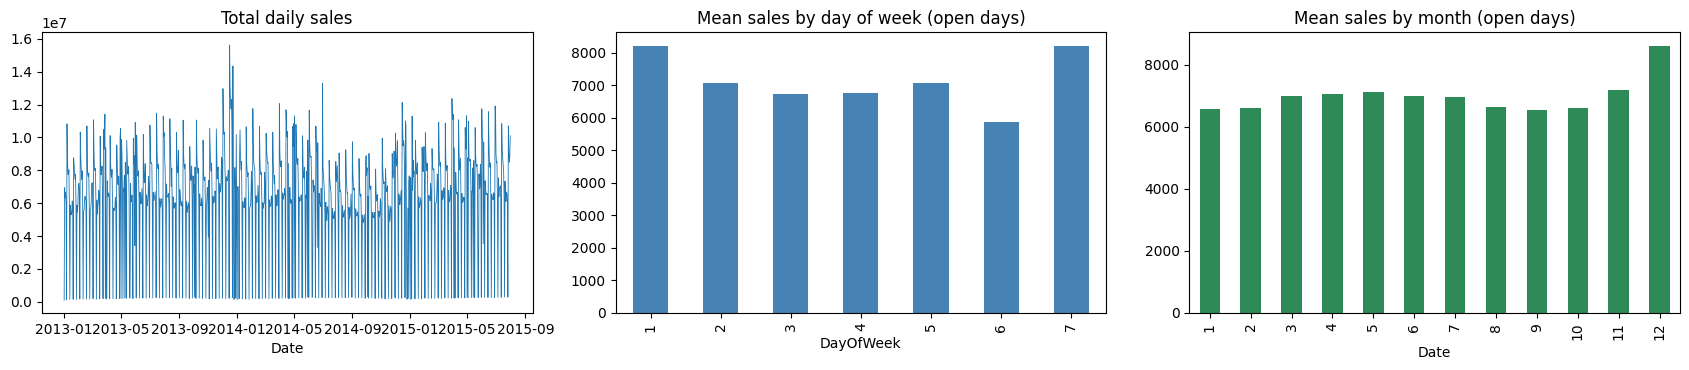

In [4]:
# Cell 5 — Data validation and EDA
def miss_table(df):
    m = df.isna().sum()
    return pd.DataFrame({"missing": m, "pct": (100 * m / len(df)).round(2)}).query("missing > 0")

print("Missing values, pool_raw:\n", miss_table(pool_raw).to_string() if len(miss_table(pool_raw)) else "none")
print("\nMissing values, store_df:\n", miss_table(store_df).to_string())
print("\nRows per year:\n", pool_raw.groupby(pool_raw["Date"].dt.year).size().to_string())
print(f"\nShare Open==0: {(pool_raw['Open'] == 0).mean():.3%} | share Sales==0: {(pool_raw['Sales'] == 0).mean():.3%}")
print("\nStateHoliday raw value counts:\n", pool_raw["StateHoliday"].astype(str).value_counts().to_string())

all_days = pd.date_range(pool_raw["Date"].min(), pool_raw["Date"].max(), freq="D")
gaps = all_days.difference(pd.DatetimeIndex(pool_raw["Date"].unique()))
print(f"\nDate range {all_days.min().date()} -> {all_days.max().date()}; missing calendar days: {len(gaps)}")
print(f"Distinct stores: {pool_raw['Store'].nunique()} (Rossmann has ~1115)")

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
daily = pool_raw.groupby("Date")["Sales"].sum()
ax[0].plot(daily.index, daily.values, lw=0.6); ax[0].set_title("Total daily sales"); ax[0].set_xlabel("Date")
op = pool_raw[(pool_raw["Open"] == 1) & (pool_raw["Sales"] > 0)]
op.groupby("DayOfWeek")["Sales"].mean().plot.bar(ax=ax[1], color="steelblue"); ax[1].set_title("Mean sales by day of week (open days)")
op.groupby(op["Date"].dt.month)["Sales"].mean().plot.bar(ax=ax[2], color="seagreen"); ax[2].set_title("Mean sales by month (open days)")
savefig("eda_overview.png")

In [5]:
# Cell 6 — Cleaning, merge and feature engineering
MABBR = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sept", 10: "Oct", 11: "Nov", 12: "Dec"}

d = pool_raw[(pool_raw["Open"] == 1) & (pool_raw["Sales"] > 0)].copy()
d["StateHoliday"] = d["StateHoliday"].astype(str).str.strip().replace({"0.0": "0", "nan": "0"})
d = d.merge(store_df, on="Store", how="left")
d["Year"] = d["Date"].dt.year
d["Month"] = d["Date"].dt.month
d["Day"] = d["Date"].dt.day
d["WeekOfYear"] = d["Date"].dt.isocalendar().week.astype(int)
d["CompetitionOpenMonths"] = (d["Year"] - d["CompetitionOpenSinceYear"]) * 12 + (d["Month"] - d["CompetitionOpenSinceMonth"])
d["Promo2Weeks"] = np.where(d["Promo2"] == 1, (d["Year"] - d["Promo2SinceYear"]) * 52 + (d["WeekOfYear"] - d["Promo2SinceWeek"]), np.nan)
d["PromoInterval"] = d["PromoInterval"].fillna("none").astype(str)
_mab = d["Month"].map(MABBR).to_numpy()
d["PromoMonthActive"] = np.fromiter((int(m in iv.split(",")) for m, iv in zip(_mab, d["PromoInterval"].to_numpy())), dtype=int, count=len(d))

NUM_COLS = ["Store", "DayOfWeek", "Promo", "SchoolHoliday", "Year", "Month", "Day", "WeekOfYear",
            "CompetitionDistance", "CompetitionOpenMonths", "Promo2", "Promo2Weeks", "PromoMonthActive"]
CAT_COLS = ["StateHoliday", "StoreType", "Assortment", "PromoInterval"]
CONT_RAW = ["CompetitionDistance", "CompetitionOpenMonths", "Promo2Weeks"]      # jittered for near-duplicates

pool = d[["Date", "Sales", "Customers"] + NUM_COLS + CAT_COLS].reset_index(drop=True)
pool["row_id"] = np.arange(len(pool))
# Missing values stay NaN here; imputation happens inside the pipeline (cell 8).

assert not (set(["Sales", "Customers", "Date"]) & set(NUM_COLS + CAT_COLS))
assert pool["row_id"].is_unique
print("pool:", pool.shape, "| rows kept (Open==1 & Sales>0):", f"{len(pool):,d} of {len(pool_raw):,d}")
print("NaN share in numeric features:\n", pool[NUM_COLS].isna().mean().round(3)[lambda s: s > 0].to_string())

pool: (844338, 21) | rows kept (Open==1 & Sales>0): 844,338 of 1,017,209
NaN share in numeric features:
 CompetitionDistance      0.003
CompetitionOpenMonths    0.318
Promo2Weeks              0.501


block first date   last date         rows  pos.rate
B1    2013-01-01   2014-06-02     478,510     0.500
B2    2014-06-03   2014-10-21     115,037     0.521
B3    2014-10-22   2015-03-12     121,458     0.611
B4    2015-03-13   2015-07-31     129,333     0.600


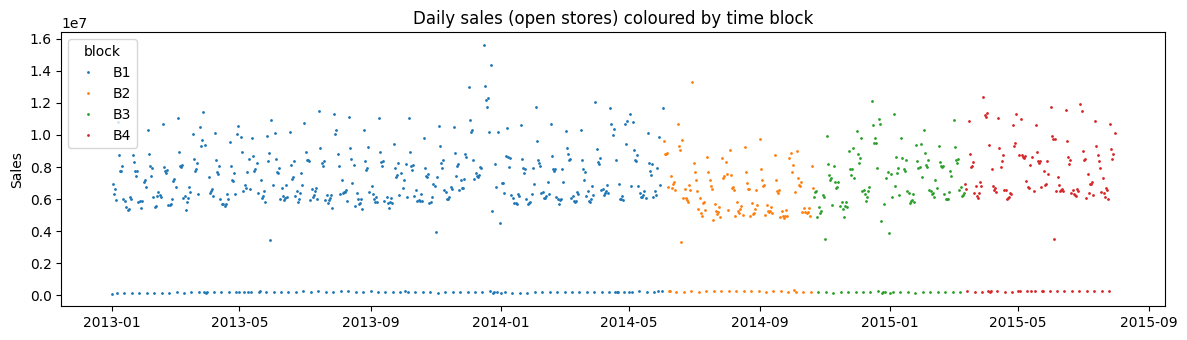

In [6]:
# Cell 7 — Time blocks and label
dates = np.sort(pool["Date"].unique())
cuts = np.round(np.cumsum(CFG["BLOCK_FRACS"]) * len(dates)).astype(int)
cuts[-1] = len(dates)
blk_of_date = np.searchsorted(cuts, np.arange(len(dates)), side="right")       # 0..3, no date straddles blocks
BLOCK_NAMES = np.array(["B1", "B2", "B3", "B4"])
pool["block"] = BLOCK_NAMES[blk_of_date[np.searchsorted(dates, pool["Date"].values)]]

store_median = pool.loc[pool["block"] == "B1"].groupby("Store")["Sales"].median()
n_before = len(pool)
pool["store_median"] = pool["Store"].map(store_median)
if pool["store_median"].isna().any():
    print(f"WARNING: {pool['store_median'].isna().sum()} rows belong to stores absent from B1 -> dropped")
    pool = pool.dropna(subset=["store_median"]).reset_index(drop=True)
    pool["row_id"] = np.arange(len(pool))
pool["y"] = (pool["Sales"] > pool["store_median"]).astype(int)
pool = pool.drop(columns=["store_median"])

BLOCKS = {}
print(f"{'block':5s} {'first date':12s} {'last date':12s} {'rows':>9s} {'pos.rate':>9s}")
for b in BLOCK_NAMES:
    sub = pool[pool["block"] == b]
    BLOCKS[b] = dict(start=sub["Date"].min(), end=sub["Date"].max(), n=len(sub), pos=sub["y"].mean())
    flag = "" if 0.3 <= BLOCKS[b]["pos"] <= 0.7 else "   <-- WARNING: positive rate outside [0.3, 0.7]"
    print(f"{b:5s} {str(BLOCKS[b]['start'].date()):12s} {str(BLOCKS[b]['end'].date()):12s} {BLOCKS[b]['n']:>9,d} {BLOCKS[b]['pos']:>9.3f}{flag}")
for a, b in zip(BLOCK_NAMES[:-1], BLOCK_NAMES[1:]):
    assert BLOCKS[a]["end"] < BLOCKS[b]["start"], "blocks overlap in time"
assert pool.loc[pool["block"] == "B1", "Store"].nunique() == pool["Store"].nunique(), "some stores missing from B1"

colors = dict(B1="tab:blue", B2="tab:orange", B3="tab:green", B4="tab:red")
daily = pool.groupby(["Date", "block"])["Sales"].sum().reset_index()
plt.figure(figsize=(12, 3.5))
for b, g in daily.groupby("block"):
    plt.plot(g["Date"], g["Sales"], ".", ms=2, color=colors[b], label=b)
plt.legend(title="block"); plt.title("Daily sales (open stores) coloured by time block"); plt.ylabel("Sales")
savefig("time_blocks.png")

## PART B — Pipeline, injection, scenarios, models

In [7]:
# Cell 8 — Preprocessing pipeline with configurable fit scope
class Pipeline:
    """Frequency-encode CAT_COLS -> mean-impute numerics -> standardise numerics (encoded columns are not scaled).
    scopes: {"encode"|"impute"|"scale": "train"|"pool"}; "pool" = train + test (validation is never used in a fit)."""
    def __init__(self, scopes=None, num_cols=None, cat_cols=None):
        self.scopes = {"encode": "train", "impute": "train", "scale": "train"}
        if scopes:
            self.scopes.update(scopes)
        self.num_cols = list(NUM_COLS if num_cols is None else num_cols)
        self.cat_cols = list(CAT_COLS if cat_cols is None else cat_cols)

    def _fit_set(self, scope, raw_train, raw_test):
        if scope == "pool" and raw_test is not None:
            return pd.concat([raw_train, raw_test], ignore_index=True)
        return raw_train

    def fit(self, raw_train, raw_test=None):
        d = self._fit_set(self.scopes["encode"], raw_train, raw_test)
        self.freq = {c: d[c].astype(str).value_counts(normalize=True).to_dict() for c in self.cat_cols}
        d = self._fit_set(self.scopes["impute"], raw_train, raw_test)
        X = d[self.num_cols].to_numpy(dtype=float)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = np.nanmean(X, axis=0)
        self.imp_mean = np.nan_to_num(m, nan=0.0)
        d = self._fit_set(self.scopes["scale"], raw_train, raw_test)
        X = d[self.num_cols].to_numpy(dtype=float)
        X = np.where(np.isnan(X), self.imp_mean, X)               # scale is fitted on the *imputed* fit set
        self.mu = X.mean(axis=0)
        sd = X.std(axis=0, ddof=0)
        sd[sd == 0] = 1.0
        self.sd = sd
        self.feature_names = list(self.num_cols) + [f"{c}_freq" for c in self.cat_cols]
        return self

    def transform(self, df):
        X = df[self.num_cols].to_numpy(dtype=float)
        X = np.where(np.isnan(X), self.imp_mean, X)
        X = (X - self.mu) / self.sd
        enc = [df[c].astype(str).map(self.freq[c]).fillna(0.0).to_numpy(dtype=float) for c in self.cat_cols]
        return np.column_stack([X] + enc).astype(np.float64)

PIPELINE_VARIANTS = {"clean": {}, "prep_L": SCEN_BY_ID["prep_L"]["params"]["scopes"],
                     "prep_M": SCEN_BY_ID["prep_M"]["params"]["scopes"], "prep_H": SCEN_BY_ID["prep_H"]["params"]["scopes"]}
print("pipeline variants:", PIPELINE_VARIANTS)

pipeline variants: {'clean': {}, 'prep_L': {'scale': 'pool'}, 'prep_M': {'scale': 'pool', 'impute': 'pool'}, 'prep_H': {'scale': 'pool', 'impute': 'pool', 'encode': 'pool'}}


In [8]:
# Cell 9 — Leakage injectors (act on raw frames before the pipeline; return ground-truth metadata)
def _replace_rows(frame, positions, src):
    out = frame.copy()
    for col in frame.columns:
        arr = frame[col].to_numpy(copy=True)
        arr[positions] = src[col].to_numpy()
        out[col] = arr
    return out

def inject_target(train, val, test, sigma, rng):
    out = []
    for df in (train, val, test):
        d_ = df.copy()
        d_["leak_feat"] = d_["y"].to_numpy(dtype=float) + rng.normal(0.0, sigma, len(d_))
        out.append(d_)
    return out[0], out[1], out[2], {"leak_feature": "leak_feat", "sigma": float(sigma)}

def inject_contamination(train, test, p, near_frac, rng):
    n = int(round(p * len(test)))
    t_pos = rng.choice(len(test), n, replace=False)
    tr_pos = rng.choice(len(train), n, replace=False)
    copies = test.iloc[t_pos].reset_index(drop=True).copy()
    n_near = int(round(near_frac * n))
    near_sel = rng.permutation(n)[:n_near]
    changed = np.zeros(n, dtype=bool)
    for col in CONT_RAW:
        old = copies[col].to_numpy(dtype=float).copy()
        new = old.copy()
        f = 1.0 + np.clip(rng.normal(0.0, 0.01, n_near), -0.04, 0.04)
        new[near_sel] = old[near_sel] * f                       # NaN stays NaN
        both_nan = np.isnan(old) & np.isnan(new)
        changed |= (new != old) & ~both_nan
        copies[col] = new
    new_train = _replace_rows(train, tr_pos, copies)
    meta = {"dup_test_row_ids": test["row_id"].to_numpy()[t_pos].tolist(),
            "dup_train_positions": tr_pos.tolist(),
            "n_exact": int(n - changed.sum()), "n_near": int(changed.sum())}
    return new_train, meta

def inject_temporal(train, b4_pool, f, rng):
    n = int(round(f * len(train)))
    pos = rng.choice(len(train), n, replace=False)
    src = b4_pool.iloc[rng.choice(len(b4_pool), n, replace=False)]
    new_train = _replace_rows(train, pos, src[train.columns])
    return new_train, {"future_row_ids": src["row_id"].to_numpy().tolist(), "train_positions": pos.tolist()}
# 'preprocessing' has no raw injection: it only selects the pipeline scopes (cell 8).

In [9]:
# Cell 10 — Scenario factory
RAW_COLS = ["row_id", "Date", "Sales", "Customers", "y", "block"] + NUM_COLS + CAT_COLS
BLOCK_POS = {b: np.flatnonzero((pool["block"] == b).to_numpy()) for b in BLOCK_NAMES}
RAW_CACHE = {}

def _hash_ids(ids):
    return hashlib.blake2b(np.asarray(ids, dtype=np.int64).tobytes(), digest_size=8).hexdigest()

def raw_samples(seed):
    """Same seed -> same raw train / val / test samples for every scenario (cached per seed only)."""
    if seed not in RAW_CACHE:
        rng = np.random.default_rng(seed)
        take = lambda b, n: pool.iloc[rng.choice(BLOCK_POS[b], min(n, len(BLOCK_POS[b])), replace=False)][RAW_COLS].reset_index(drop=True)
        tr, va, te = take("B1", CFG["N_TRAIN"]), take("B2", CFG["N_VAL"]), take("B3", CFG["N_TEST"])
        RAW_CACHE.clear()                                   # keep memory small: one seed at a time
        RAW_CACHE[seed] = dict(train=tr, val=va, test=te, test_hash=_hash_ids(te["row_id"]))
    return RAW_CACHE[seed]

@dataclass
class ScenarioData:
    X_train: np.ndarray; y_train: np.ndarray
    X_val: np.ndarray; y_val: np.ndarray
    X_test: np.ndarray; y_test: np.ndarray
    feature_names: list
    ts_train: np.ndarray; ts_test: np.ndarray
    row_id_train: np.ndarray; row_id_test: np.ndarray
    meta: dict
    raw_cols: list
    raw_train: object = None; raw_val: object = None; raw_test: object = None

def assemble(seed, scenario_id, injections, scopes=None, extra_num=None, rng_tag=None):
    """injections: list of (type, params). Used by build_scenario and by the combined-leak demo (cell 34)."""
    base = raw_samples(seed)
    train, val, test = base["train"].copy(), base["val"].copy(), base["test"].copy()
    b4 = pool.iloc[BLOCK_POS["B4"]][RAW_COLS].reset_index(drop=True)
    tag = rng_tag or scenario_id
    rng = np.random.default_rng(np.random.SeedSequence([seed, zlib.crc32(tag.encode()) % 2 ** 31]))
    meta = {"scenario_id": scenario_id, "seed": seed}
    extra = list(extra_num or [])
    truth = {t: False for t in LEAK_TYPES}
    for typ, prm in injections:
        truth[typ] = True
        if typ == "target":
            train, val, test, m = inject_target(train, val, test, prm["sigma"], rng); extra.append("leak_feat")
        elif typ == "contamination":
            train, m = inject_contamination(train, test, prm["p"], prm["near_frac"], rng)
        elif typ == "temporal":
            train, m = inject_temporal(train, b4, prm["f"], rng)
        else:
            raise ValueError(typ)
        meta[typ] = m
    if scopes and any(v == "pool" for v in scopes.values()):
        truth["preprocessing"] = True
    meta["truth"] = truth
    meta["scopes"] = scopes or {}
    pipe = Pipeline(scopes=scopes, num_cols=NUM_COLS + extra).fit(train, test)
    scn = ScenarioData(
        X_train=pipe.transform(train), y_train=train["y"].to_numpy(),
        X_val=pipe.transform(val), y_val=val["y"].to_numpy(),
        X_test=pipe.transform(test), y_test=test["y"].to_numpy(),
        feature_names=pipe.feature_names,
        ts_train=train["Date"].to_numpy(), ts_test=test["Date"].to_numpy(),
        row_id_train=train["row_id"].to_numpy(), row_id_test=test["row_id"].to_numpy(),
        meta=meta, raw_cols=list(train.columns), raw_train=train, raw_val=val, raw_test=test)
    assert _hash_ids(scn.row_id_test) == base["test_hash"], "raw test rows changed between scenarios"
    assert scn.X_train.shape[0] == len(scn.y_train) and scn.X_test.shape[0] == len(scn.y_test)
    assert scn.X_train.shape[1] == scn.X_test.shape[1] == scn.X_val.shape[1] == len(scn.feature_names)
    assert np.isfinite(scn.X_train).all() and np.isfinite(scn.X_test).all()
    return scn

def build_scenario(seed, scenario_id, extra_num=None):
    sc = SCEN_BY_ID[scenario_id]
    inj, scopes = [], None
    if sc["type"] in ("target", "contamination", "temporal"):
        inj = [(sc["type"], sc["params"])]
    elif sc["type"] == "preprocessing":
        scopes = sc["params"]["scopes"]
    scn = assemble(seed, scenario_id, inj, scopes=scopes, extra_num=extra_num)
    t = scn.meta["truth"]
    want = {k: (sc["type"] == k) for k in LEAK_TYPES}
    assert t == want, f"truth mismatch for {scenario_id}: {t}"
    return scn

_s = build_scenario(0, "clean")
print("clean scenario:", _s.X_train.shape, _s.X_val.shape, _s.X_test.shape, "| features:", len(_s.feature_names))
del _s

clean scenario: (30000, 17) (8000, 17) (10000, 17) | features: 17


In [10]:
# Cell 11 — Models, black-box wrapper, metrics
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, log_loss, roc_curve
from xgboost import XGBClassifier

def make_model(name, seed):
    P = MODEL_PARAMS[name]
    if name == "logreg": return LogisticRegression(random_state=seed, **P)
    if name == "rf":     return RandomForestClassifier(random_state=seed, **P)
    if name == "xgb":    return XGBClassifier(random_state=seed, n_jobs=-1, **P)
    if name == "mlp":    return MLPClassifier(random_state=seed, **P)
    raise ValueError(name)

class BlackBox:
    """Exposes only predict / predict_proba (and counts calls). The detector may use nothing else."""
    def __init__(self, model, name):
        self._model = model
        self.name = name
        self.n_calls = 0
    def predict(self, X):
        self.n_calls += 1
        return self._model.predict(X)
    def predict_proba(self, X):
        self.n_calls += 1
        return np.asarray(self._model.predict_proba(X))

def train_and_eval(scn, name):
    seed = scn.meta["seed"]
    m = make_model(name, seed)
    t0 = time.time()
    if name == "xgb":
        m.fit(scn.X_train, scn.y_train, eval_set=[(scn.X_val, scn.y_val)], verbose=False)
    else:
        m.fit(scn.X_train, scn.y_train)
    fit_s = time.time() - t0
    bb = BlackBox(m, name)
    met = {"fit_seconds": fit_s}
    for split, X, y in (("train", scn.X_train, scn.y_train), ("val", scn.X_val, scn.y_val), ("test", scn.X_test, scn.y_test)):
        p = bb.predict_proba(X)
        assert p.shape == (len(X), 2) and p.min() >= 0 and p.max() <= 1
        p1 = p[:, 1]
        met[f"auc_{split}"] = roc_auc_score(y, p1)
        met[f"acc_{split}"] = accuracy_score(y, p1 >= 0.5)
        met[f"f1_{split}"] = f1_score(y, p1 >= 0.5)
        met[f"logloss_{split}"] = log_loss(y, np.clip(p1, 1e-7, 1 - 1e-7))
    bb.n_calls = 0
    return bb, met

In [11]:
# Cell 12 — Injector and pipeline sanity tests (seed 0). Raises if anything fails.
from scipy.stats import norm
_results = []
def check(name, cond, info=""):
    _results.append((name, bool(cond)))
    print(("PASS  " if cond else "FAIL  ") + name + (f"   [{info}]" if info else ""))

S = {sid: build_scenario(0, sid) for sid in ["clean", "target_L", "target_M", "target_H", "contam_L", "contam_M", "contam_H",
                                              "temporal_L", "temporal_M", "temporal_H", "prep_L"]}
# --- clean
c = S["clean"]
enc_mask = np.array([n.endswith("_freq") for n in c.feature_names])
sd0 = c.X_train.std(axis=0) > 1e-9
check("clean: train mean ~ 0", np.abs(c.X_train[:, ~enc_mask & sd0].mean(0)).max() < 1e-9, f"{np.abs(c.X_train[:, ~enc_mask & sd0].mean(0)).max():.1e}")
check("clean: train std ~ 1", np.abs(c.X_train[:, ~enc_mask & sd0].std(0) - 1).max() < 1e-9)
check("clean: no NaN", all(np.isfinite(s.X_train).all() and np.isfinite(s.X_test).all() for s in S.values()))
check("test rows identical across scenarios", all(np.array_equal(s.row_id_test, c.row_id_test) for s in S.values()))
# --- target
for sid, sig in (("target_L", 1.0), ("target_M", 0.5), ("target_H", 0.15)):
    s = S[sid]; j = s.feature_names.index("leak_feat")
    a = roc_auc_score(s.y_test, s.X_test[:, j]); th = norm.cdf(1 / (sig * np.sqrt(2)))
    check(f"{sid}: single-feature AUC within 0.03 of theory", abs(a - th) <= 0.03, f"{a:.3f} vs {th:.3f}")
# --- contamination
for sid in ("contam_L", "contam_M", "contam_H"):
    s = S[sid]; m = s.meta["contamination"]
    tr_rows = {r.tobytes() for r in np.ascontiguousarray(s.X_train)}
    n_match = sum(r.tobytes() in tr_rows for r in np.ascontiguousarray(s.X_test))
    check(f"{sid}: exactly n_exact test rows bit-identical in train", n_match == m["n_exact"], f"{n_match} vs {m['n_exact']}")
    rt = s.raw_train.iloc[m["dup_train_positions"]].reset_index(drop=True)
    rs = s.raw_test.set_index("row_id").loc[rt["row_id"]].reset_index()
    ok = True
    for col in CONT_RAW:
        a, b = rt[col].to_numpy(float), rs[col].to_numpy(float)
        f = np.isfinite(a) & np.isfinite(b)
        ok &= bool((np.abs(a[f] - b[f]) / np.maximum(np.abs(b[f]), 1e-9) <= 0.05).all())
    check(f"{sid}: near copies within 5% relative distance", ok)
# --- temporal
for sid, f in (("temporal_L", 0.05), ("temporal_M", 0.15), ("temporal_H", 0.40)):
    s = S[sid]; n = int((s.ts_train > s.ts_test.max()).sum())
    check(f"{sid}: train rows after test period == round(f*N_TRAIN)", n == int(round(f * CFG["N_TRAIN"])), f"{n}")
check("clean twin: 0 train rows after test period", int((c.ts_train > c.ts_test.max()).sum()) == 0)
# --- preprocessing
s = S["prep_L"]; allX = np.vstack([s.X_train, s.X_test]); em = np.array([n.endswith("_freq") for n in s.feature_names])
sdp = allX.std(0) > 1e-9
check("prep_L: pooled mean/std = 0/1", np.abs(allX[:, ~em & sdp].mean(0)).max() < 1e-9 and np.abs(allX[:, ~em & sdp].std(0) - 1).max() < 1e-9)
check("prep_L: train-only std is not 1", np.abs(s.X_train[:, ~em & sdp].std(0) - 1).max() > 1e-4)
if not all(ok for _, ok in _results):
    raise AssertionError("Sanity tests failed: " + ", ".join(n for n, ok in _results if not ok))
print(f"\nAll {len(_results)} sanity tests passed.")
del S; gc.collect()

PASS  clean: train mean ~ 0   [7.0e-14]
PASS  clean: train std ~ 1
PASS  clean: no NaN
PASS  test rows identical across scenarios
PASS  target_L: single-feature AUC within 0.03 of theory   [0.759 vs 0.760]
PASS  target_M: single-feature AUC within 0.03 of theory   [0.923 vs 0.921]
PASS  target_H: single-feature AUC within 0.03 of theory   [1.000 vs 1.000]
PASS  contam_L: exactly n_exact test rows bit-identical in train   [100 vs 100]
PASS  contam_L: near copies within 5% relative distance
PASS  contam_M: exactly n_exact test rows bit-identical in train   [250 vs 250]
PASS  contam_M: near copies within 5% relative distance
PASS  contam_H: exactly n_exact test rows bit-identical in train   [1001 vs 1001]
PASS  contam_H: near copies within 5% relative distance
PASS  temporal_L: train rows after test period == round(f*N_TRAIN)   [1500]
PASS  temporal_M: train rows after test period == round(f*N_TRAIN)   [4500]
PASS  temporal_H: train rows after test period == round(f*N_TRAIN)   [12000]
PAS

0

        auc_train  acc_train  f1_train  logloss_train  auc_val  acc_val  f1_val  logloss_val  auc_test  acc_test  f1_test  logloss_test  fit_seconds
model                                                                                                                                               
logreg     0.8521     0.8195    0.8053         0.4558   0.8534   0.8556  0.8532       0.4317    0.8418    0.7734   0.8000        0.4857       0.3494
rf         0.9882     0.9300    0.9294         0.1939   0.9135   0.8616  0.8616       0.3639    0.8902    0.8258   0.8561        0.4055       9.3341
xgb        0.9671     0.9008    0.9000         0.2485   0.9214   0.8644  0.8652       0.3532    0.8964    0.8337   0.8637        0.4030       2.6994
mlp        0.9227     0.8483    0.8451         0.3550   0.8371   0.6461  0.7332       0.7510    0.8343    0.7389   0.8196        0.8297       6.5749


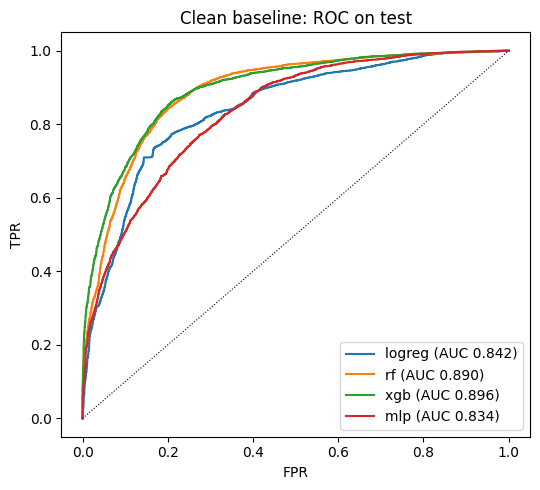

logreg  test AUC 0.842: ok | val-test AUC gap +0.0116  (time-drift signal)
rf      test AUC 0.890: ok | val-test AUC gap +0.0233  (time-drift signal)
xgb     test AUC 0.896: ok | val-test AUC gap +0.0250  (time-drift signal)
mlp     test AUC 0.834: ok | val-test AUC gap +0.0028  (time-drift signal)


In [12]:
# Cell 13 — Clean baseline (seed 0)
clean0 = build_scenario(0, "clean")
rows, BASE_BB = [], {}
for mn in MODELS:
    bb, met = train_and_eval(clean0, mn)
    BASE_BB[mn] = bb
    rows.append(dict(model=mn, **{k: round(v, 4) for k, v in met.items()}))
base_tbl = pd.DataFrame(rows).set_index("model")
show = [f"{m}_{s}" for s in ("train", "val", "test") for m in ("auc", "acc", "f1", "logloss")] + ["fit_seconds"]
print(base_tbl[show].to_string())

plt.figure(figsize=(5.5, 5))
for mn in MODELS:
    p = BASE_BB[mn].predict_proba(clean0.X_test)[:, 1]
    fpr, tpr, _ = roc_curve(clean0.y_test, p)
    plt.plot(fpr, tpr, label=f"{mn} (AUC {roc_auc_score(clean0.y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k:", lw=0.8); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("Clean baseline: ROC on test"); plt.legend()
savefig("clean_baseline_roc.png")

for mn in MODELS:
    a = base_tbl.loc[mn, "auc_test"]
    msg = "ok" if 0.60 <= a <= 0.97 else "OUTSIDE [0.60, 0.97] -> check for accidental leakage in the clean setting"
    print(f"{mn:7s} test AUC {a:.3f}: {msg} | val-test AUC gap {base_tbl.loc[mn, 'auc_val'] - a:+.4f}  (time-drift signal)")
del clean0

## PART C — The leakage detector

`LeakageDetector(model, X_train, y_train, X_test, y_test, feature_names, ts_train, ts_test, row_id_train, row_id_test, seed, thresholds)` sees only processed arrays, labels, timestamps, feature names and a `BlackBox` (`predict` / `predict_proba`). Data-only signals are computed once per scenario and cached; model-level signals are recomputed per model. Wherever the detector needs to re-train something it uses a fixed surrogate probe (`HistGradientBoostingClassifier`), because the evaluated model is a black box that cannot be cloned.

In [13]:
# Cell 14 — Detector utilities
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.neighbors import NearestNeighbors

def safe_auc(y, p):
    y = np.asarray(y)
    if len(np.unique(y)) < 2:
        return float("nan")
    return float(roc_auc_score(y, p))

def clip01(x):
    return float(np.clip(x, 0.0, 1.0))

def robust_z(values):
    v = np.asarray(values, dtype=float)
    med = np.nanmedian(v)
    mad = np.nanmedian(np.abs(v - med))
    return (v - med) / (1.4826 * mad + 1e-9)

def row_hash(X, decimals=6):
    """Round -> bytes -> blake2b (64-bit digest as uint64), one hash per row."""
    Xr = np.ascontiguousarray(np.round(np.asarray(X, dtype=float), decimals) + 0.0)     # +0.0 maps -0.0 to 0.0
    out = np.empty(len(Xr), dtype=np.uint64)
    for i in range(len(Xr)):
        out[i] = int.from_bytes(hashlib.blake2b(Xr[i].tobytes(), digest_size=8).digest(), "little")
    return out

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return (max(0.0, c - h), min(1.0, c + h))

def binom_excess_test(k, n, base_rate):
    base = float(min(max(base_rate, 1e-4), 1 - 1e-9))
    return float(stats.binomtest(int(k), int(n), base, alternative="greater").pvalue)

def stratified_subsample(y, n, rng):
    y = np.asarray(y)
    if n >= len(y):
        return np.arange(len(y))
    idx = []
    for c in np.unique(y):
        ci = np.flatnonzero(y == c)
        idx.append(rng.choice(ci, max(1, int(round(n * len(ci) / len(y)))), replace=False))
    return np.sort(np.concatenate(idx))

def surrogate(seed):
    return HistGradientBoostingClassifier(max_iter=100, early_stopping=False, random_state=seed)

def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray): return to_jsonable(o.tolist())
    if isinstance(o, (bool, np.bool_)): return bool(o)
    if isinstance(o, (int, np.integer)): return int(o)
    if isinstance(o, (float, np.floating)): return float(o) if np.isfinite(o) else None
    if isinstance(o, (pd.Timestamp, np.datetime64)): return str(o)
    return o

def _days(ts):
    ts = np.asarray(ts)
    if np.issubdtype(ts.dtype, np.datetime64):
        return ts.astype("datetime64[D]").astype("int64").astype(float)
    return ts.astype(float)

# --- unit tests
_a = np.array([[1.0, 2.0], [1.0, 2.0], [3.0, 4.0]])
_h = row_hash(_a)
assert _h[0] == _h[1] and _h[0] != _h[2], "identical rows must hash equal"
_v = np.r_[np.random.default_rng(0).normal(size=50), 25.0]
assert robust_z(_v)[-1] > 10, "outlier must have a large robust z"
assert 0 < wilson_ci(5, 10)[0] < 0.5 < wilson_ci(5, 10)[1] < 1
assert binom_excess_test(50, 100, 0.05) < 1e-6 and binom_excess_test(5, 100, 0.05) > 0.3
print("utility unit tests passed")

utility unit tests passed


In [14]:
# Cell 15 — Target-leakage module
def single_strength(x, y, seed):
    """max(rank AUC in both directions, 3-fold CV AUC of a depth-4 tree on that single feature)."""
    r = safe_auc(y, x)
    r = max(r, 1 - r) if np.isfinite(r) else 0.0
    try:
        cv = float(cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=seed), x.reshape(-1, 1), y,
                                   cv=3, scoring="roc_auc").mean())
    except Exception:
        cv = 0.0
    return max(r, cv)

def target_data_level(X_train, y_train, X_test, y_test, seed):
    rng = np.random.default_rng(seed + 1)
    n, d_ = X_train.shape
    idx = rng.choice(n, min(CFG["MI_SUBSAMPLE"], n), replace=False)
    Xs, ys = X_train[idx], y_train[idx]
    disc = np.array([len(np.unique(Xs[:, j])) <= 10 for j in range(d_)])
    mi = mutual_info_classif(Xs, ys, discrete_features=disc, n_neighbors=3, random_state=seed)
    p = ys.mean()
    Hy = float(-(p * np.log(p) + (1 - p) * np.log(1 - p))) if 0 < p < 1 else 1.0
    z = robust_z(mi)
    top = [int(j) for j in np.argsort(-mi)[:CFG["TOP_K"]]]
    a = {j: 0.5 * (single_strength(Xs[:, j], ys, seed) + single_strength(X_test[:, j], y_test, seed)) for j in top}
    ab = rng.choice(n, min(CFG["SURR_ROWS"], n), replace=False)
    Xa, ya = X_train[ab], y_train[ab]
    base = float(cross_val_score(surrogate(seed), Xa, ya, cv=3, scoring="roc_auc").mean())
    drop = {}
    for j in top:
        cols = [c for c in range(d_) if c != j]
        drop[j] = base - float(cross_val_score(surrogate(seed), Xa[:, cols], ya, cv=3, scoring="roc_auc").mean())
    return dict(mi=mi, mi_norm=mi / Hy, z=z, top=top, a=a, drop=drop, base_auc=base)

def perm_importance(bb, X, y, rng):
    """Black-box permutation importance (AUC loss) on <= PERM_ROWS rows."""
    idx = rng.choice(len(X), min(CFG["PERM_ROWS"], len(X)), replace=False)
    Xs, ys = X[idx], y[idx]
    base = safe_auc(ys, bb.predict_proba(Xs)[:, 1])
    imp = np.zeros(X.shape[1])
    Xp = Xs.copy()
    for j in range(X.shape[1]):
        losses = []
        for _ in range(CFG["PERM_REPEATS"]):
            Xp[:, j] = Xs[rng.permutation(len(Xs)), j]
            losses.append(base - safe_auc(ys, bb.predict_proba(Xp)[:, 1]))
        Xp[:, j] = Xs[:, j]
        imp[j] = float(np.mean(losses))
    return imp

def target_report(dl, imp, names, thr):
    d_ = len(names)
    pos = np.clip(imp, 0, None)
    share = pos / pos.sum() if pos.sum() > 0 else np.zeros(d_)
    s_mi = np.array([clip01(np.log10(max(z, 1.0)) / 2) for z in dl["z"]])
    s_auc, s_abl = np.zeros(d_), np.zeros(d_)
    for j in dl["top"]:
        s_auc[j] = clip01((dl["a"][j] - 0.85) / 0.15)
        s_abl[j] = clip01(dl["drop"][j] / 0.05)
    s_perm = np.array([clip01((s - 0.3) / 0.5) for s in share])
    f = 0.35 * s_mi + 0.30 * s_auc + 0.20 * s_abl + 0.15 * s_perm
    order = np.argsort(-f)
    table = [dict(feature=names[j], f=float(f[j]), s_mi=float(s_mi[j]), s_auc=float(s_auc[j]), s_abl=float(s_abl[j]),
                  s_perm=float(s_perm[j]), mi_z=float(dl["z"][j]), single_auc=float(dl["a"].get(j, np.nan)),
                  abl_drop=float(dl["drop"].get(j, np.nan)), perm_share=float(share[j])) for j in order[:10]]
    score = float(f.max())
    suspects = [dict(feature=names[j], score=float(f[j])) for j in order if f[j] >= thr]
    sig = dict(mi_z_max=float(np.max(dl["z"])), mi_norm_max=float(np.max(dl["mi_norm"])),
               single_auc_max=float(max(dl["a"].values())), abl_drop_max=float(max(dl["drop"].values())),
               perm_share_max=float(share.max()), s_mi_max=float(s_mi.max()), s_auc_max=float(s_auc.max()),
               s_abl_max=float(s_abl.max()), s_perm_max=float(s_perm.max()))
    return dict(score=score, flag=bool(score >= thr),
                evidence=dict(suspect_features=suspects, ranked=table)), sig

In [15]:
# Cell 16 — Contamination module
def contamination_data_level(X_train, X_test, row_id_train, row_id_test, seed):
    rng = np.random.default_rng(seed + 17)
    dec = CFG["ROUND_DECIMALS"]
    n_tr, n_te = len(X_train), len(X_test)
    h_tr, h_te = row_hash(X_train, dec), row_hash(X_test, dec)
    # 1) exact overlap
    in_train = np.isin(h_te, h_tr)
    k_exact = int(in_train.sum())
    exact_rate = k_exact / n_te
    hold = rng.choice(n_tr, min(CFG["NN_HOLDOUT"], n_tr // 2), replace=False)
    rest = np.ones(n_tr, dtype=bool); rest[hold] = False
    b_exact = float(np.isin(h_tr[hold], h_tr[rest]).mean())
    p_exact = binom_excess_test(k_exact, n_te, b_exact)
    excess_exact = max(0.0, exact_rate - b_exact) if p_exact < 0.01 else 0.0
    # 2) near duplicates (kd-tree on the full train)
    nn_full = NearestNeighbors(n_neighbors=1, algorithm="kd_tree").fit(X_train)
    d_all, i_all = nn_full.kneighbors(X_test)
    d_all, i_all = d_all[:, 0], i_all[:, 0]
    q = rng.choice(n_te, min(CFG["NN_QUERY"], n_te), replace=False)
    d_test = d_all[q]
    nn_base = NearestNeighbors(n_neighbors=1, algorithm="kd_tree").fit(X_train[rest])
    d_base = nn_base.kneighbors(X_train[hold])[0][:, 0]
    eps = max(float(np.quantile(d_base, 0.05)), 1e-6)
    o, b = float((d_test <= eps).mean()), float((d_base <= eps).mean())
    k_nn = int((d_test <= eps).sum())
    p_nn = binom_excess_test(k_nn, len(d_test), b)
    excess_nn = max(0.0, (o - b) / (1 - b)) if p_nn < 0.01 else 0.0
    near_mask = d_all <= eps
    # matched rows (used by the temporal module, the memorisation gap and the remediation)
    test_dup = np.zeros(n_te, dtype=bool); train_dup = np.zeros(n_tr, dtype=bool)
    if excess_exact > 0:
        test_dup |= in_train
        train_dup |= np.isin(h_tr, h_te[in_train])
    if excess_nn > 0:
        test_dup |= near_mask
        train_dup[i_all[near_mask]] = True
    return dict(exact_rate=exact_rate, b_exact=b_exact, p_exact=p_exact, excess_exact=excess_exact,
                nn_rate=o, nn_base=b, eps=eps, p_nn=p_nn, excess_nn=excess_nn,
                s_dup=clip01(excess_exact / 0.02), s_nn=clip01(excess_nn / 0.05),
                n_exact=int((in_train & test_dup).sum()), n_near=int((near_mask & ~in_train & test_dup).sum()),
                test_dup_mask=test_dup, train_dup_mask=train_dup,
                dup_test_row_ids=np.asarray(row_id_test)[test_dup].tolist(),
                dup_train_row_ids=np.asarray(row_id_train)[train_dup].tolist())

def contamination_report(dl, bb, X_test, y_test, thr):
    m = dl["test_dup_mask"]
    gap, s_mem = 0.0, 0.0
    if m.sum() >= 50 and (~m).sum() >= 50:
        gm, gu = safe_auc(y_test[m], bb.predict_proba(X_test[m])[:, 1]), safe_auc(y_test[~m], bb.predict_proba(X_test[~m])[:, 1])
        if np.isfinite(gm) and np.isfinite(gu):
            gap = gm - gu
        s_mem = clip01(gap / 0.2)
    score = 0.8 * max(dl["s_dup"], dl["s_nn"]) + 0.2 * s_mem
    ev = dict(n_exact=dl["n_exact"], n_near=dl["n_near"], dup_test_row_ids=dl["dup_test_row_ids"],
              dup_train_row_ids=dl["dup_train_row_ids"], excess_exact=dl["excess_exact"], excess_nn=dl["excess_nn"])
    sig = dict(excess_exact=dl["excess_exact"], excess_nn=dl["excess_nn"], mem_gap=float(gap),
               s_dup=dl["s_dup"], s_nn=dl["s_nn"], s_mem=s_mem)
    return dict(score=float(score), flag=bool(score >= thr), evidence=ev), sig

In [16]:
# Cell 17 — Temporal-leakage module
def temporal_data_level(X_train, y_train, X_test, y_test, ts_train, ts_test, row_id_train, train_dup_mask, seed):
    if ts_train is None or ts_test is None:
        return dict(abstain=True, reason="no timestamp")
    tt, te = _days(ts_train), _days(ts_test)
    keep = ~train_dup_mask                                    # matched duplicates are excluded first
    n_keep = max(int(keep.sum()), 1)
    test_start, test_end = float(np.quantile(te, 0.01)), float(te.max())
    over = keep & (tt >= test_start)
    overlap_frac = float(over.sum() / n_keep)
    future_frac = float((keep & (tt > test_end)).sum() / n_keep)
    # time-ordered re-split
    Xp = np.vstack([X_train[keep], X_test]); yp = np.r_[y_train[keep], y_test]; tp = np.r_[tt[keep], te]
    n_tr, n_te = int(keep.sum()), len(te)
    order = np.argsort(tp, kind="stable")
    new_tr, new_te = order[:n_tr], order[-n_te:]
    delta, auc_given, auc_resplit = 0.0, float("nan"), float("nan")
    if not np.array_equal(np.sort(new_tr), np.arange(n_tr)):  # for a correctly ordered split the rows are identical -> delta = 0
        auc_given = safe_auc(y_test, surrogate(seed).fit(X_train[keep], y_train[keep]).predict_proba(X_test)[:, 1])
        auc_resplit = safe_auc(yp[new_te], surrogate(seed).fit(Xp[new_tr], yp[new_tr]).predict_proba(Xp[new_te])[:, 1])
        delta = float(auc_given - auc_resplit)
    day_str = lambda v: str(np.datetime64(int(v), "D")) if np.issubdtype(np.asarray(ts_train).dtype, np.datetime64) else float(v)
    return dict(abstain=False, overlap_frac=overlap_frac, future_frac=future_frac, delta=delta,
                auc_given=auc_given, auc_resplit=auc_resplit,
                train_max=day_str(tt[keep].max()), test_min=day_str(te.min()), test_max=day_str(test_end),
                suggested_cut=day_str(test_start), post_cut_train_row_ids=np.asarray(row_id_train)[over].tolist())

def temporal_report(dl, thr):
    if dl["abstain"]:
        return dict(score=float("nan"), flag=False, evidence=dict(reason=dl["reason"])), \
               dict(overlap_frac=float("nan"), future_frac=float("nan"), resplit_delta=float("nan"))
    score = 0.7 * clip01(dl["overlap_frac"] / 0.05) + 0.3 * clip01(dl["delta"] / 0.05)
    ev = {k: dl[k] for k in ("train_max", "test_min", "test_max", "suggested_cut", "overlap_frac", "future_frac")}
    ev["post_cut_train_row_ids"] = dl["post_cut_train_row_ids"]
    return dict(score=float(score), flag=bool(score >= thr), evidence=ev), \
           dict(overlap_frac=dl["overlap_frac"], future_frac=dl["future_frac"], resplit_delta=dl["delta"])

In [17]:
# Cell 18 — Preprocessing-leakage module (exact fingerprints on the processed arrays only)
def preprocessing_data_level(X_train, X_test, names):
    tol = CFG["FP_TOL"]
    pooled = np.vstack([X_train, X_test])
    d_ = X_train.shape[1]
    nd = [len(np.unique(pooled[:, j])) for j in range(d_)]
    enc = [j for j in range(d_) if 2 <= nd[j] <= 10 and pooled[:, j].min() >= 0 and pooled[:, j].max() <= 1]
    std_ok = lambda x: abs(x.mean()) < tol and abs(x.std() - 1) < tol
    mm_ok = lambda x: abs(x.min()) < tol and abs(x.max() - 1) < tol
    ev = dict(scale={}, imputation={}, encoding={})
    # 1) scaler
    for j in range(d_):
        if nd[j] <= 20 or j in enc:
            continue
        tr, po = X_train[:, j], pooled[:, j]
        if std_ok(tr) or mm_ok(tr): ev["scale"][names[j]] = "train"
        elif std_ok(po) or mm_ok(po): ev["scale"][names[j]] = "pool"
    # 2) imputation spike
    for j in range(d_):
        if nd[j] <= 20 or j in enc:
            continue
        vals, cnt = np.unique(X_train[:, j], return_counts=True)
        v, fr = vals[np.argmax(cnt)], cnt.max() / len(X_train)
        if not (0.01 <= fr <= 0.80):
            continue
        m_tr = X_train[X_train[:, j] != v, j].mean()
        po_ns = pooled[pooled[:, j] != v, j]
        m_po = po_ns.mean() if len(po_ns) else np.nan
        if abs(v - m_tr) < tol: ev["imputation"][names[j]] = "train"
        elif abs(v - m_po) < tol and abs(v - m_tr) > 10 * tol: ev["imputation"][names[j]] = "pool"
    # 3) frequency encoding
    for j in enc:
        vals = np.unique(X_train[:, j]); vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        tr_ok = all(abs((X_train[:, j] == v).mean() - v) < 1e-9 for v in vals)
        po_ok = all(abs((pooled[:, j] == v).mean() - v) < 1e-9 for v in vals)
        if tr_ok: ev["encoding"][names[j]] = "train"
        elif po_ok: ev["encoding"][names[j]] = "pool"
    frac = lambda dct: (sum(v == "pool" for v in dct.values()) / len(dct)) if dct else 0.0
    return dict(s_scale=frac(ev["scale"]), s_imp=frac(ev["imputation"]), s_enc=frac(ev["encoding"]), evidence=ev,
                n_fingerprinted=sum(len(v) for v in ev.values()))

def preprocessing_report(dl, thr):
    score = max(dl["s_scale"], dl["s_imp"], dl["s_enc"])
    ev = dict(fingerprints=dl["evidence"], note=("no fingerprintable column" if dl["n_fingerprinted"] == 0 else "ok"))
    return dict(score=float(score), flag=bool(score >= thr), evidence=ev), \
           dict(fp_scale=dl["s_scale"], fp_imp=dl["s_imp"], fp_enc=dl["s_enc"])

In [18]:
# Cell 19 — Adversarial validation (supporting signal only; weight 0 in every score)
from scipy.stats import spearmanr

def adversarial_validation(X_train, X_test, ts_train, ts_test, names, seed):
    rng = np.random.default_rng(seed + 29)
    k = CFG["ADV_SUBSAMPLE"] // 2
    i_tr = rng.choice(len(X_train), min(k, len(X_train)), replace=False)
    i_te = rng.choice(len(X_test), min(k, len(X_test)), replace=False)
    Xa = np.vstack([X_train[i_tr], X_test[i_te]]); ya = np.r_[np.zeros(len(i_tr)), np.ones(len(i_te))]
    proxies = []
    keep_cols = list(range(Xa.shape[1]))
    if ts_train is not None and ts_test is not None:
        ta = np.r_[_days(ts_train)[i_tr], _days(ts_test)[i_te]]
        for j in range(Xa.shape[1]):
            if Xa[:, j].std() < 1e-12:
                continue
            r = spearmanr(Xa[:, j], ta).correlation
            if np.isfinite(r) and abs(r) >= 0.8:
                proxies.append(names[j])
        keep_cols = [j for j in keep_cols if names[j] not in proxies]
    rf = RandomForestClassifier(n_estimators=100, max_depth=8, n_jobs=-1, random_state=seed)
    oof = cross_val_predict(rf, Xa[:, keep_cols], ya, cv=StratifiedKFold(3, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    adv_auc = safe_auc(ya, oof)
    rf.fit(Xa[:, keep_cols], ya)
    top = np.argsort(-rf.feature_importances_)[:5]
    return dict(adv_auc=float(adv_auc), time_proxies=proxies,
                top_features=[dict(feature=names[keep_cols[i]], importance=float(rf.feature_importances_[i])) for i in top])

In [19]:
# Cell 20 — Model-level signals (black-box train-vs-test gaps)
def model_gap_signals(bb, X_train, y_train, X_test, y_test, seed):
    rng = np.random.default_rng(seed + 31)
    i = rng.choice(len(X_train), min(len(X_train), 20000), replace=False)
    ptr, pte = bb.predict_proba(X_train[i]), bb.predict_proba(X_test)
    return dict(gap_auc=float(safe_auc(y_train[i], ptr[:, 1]) - safe_auc(y_test, pte[:, 1])),
                gap_conf=float(ptr.max(axis=1).mean() - pte.max(axis=1).mean()))

In [20]:
# Cell 21 — Remediation and inflation estimate (black-box AUC before vs after remediation)
def estimate_inflation(bb, X_test, y_test, names, tgt_rep, con_dl, tmp_dl, flags, rng):
    auc_given = safe_auc(y_test, bb.predict_proba(X_test)[:, 1])
    by = {t: 0.0 for t in LEAK_TYPES}
    if flags["target"] and tgt_rep["evidence"]["suspect_features"]:
        Xp = X_test.copy()
        for s in tgt_rep["evidence"]["suspect_features"]:
            j = names.index(s["feature"]); Xp[:, j] = rng.permutation(Xp[:, j])      # within-test permutation
        by["target"] = auc_given - safe_auc(y_test, bb.predict_proba(Xp)[:, 1])
    if flags["contamination"]:
        keep = ~con_dl["test_dup_mask"]
        if keep.sum() > 50:
            by["contamination"] = auc_given - safe_auc(y_test[keep], bb.predict_proba(X_test[keep])[:, 1])
    if flags["temporal"] and not tmp_dl.get("abstain", False):
        by["temporal"] = max(0.0, tmp_dl["delta"])
    by["preprocessing"] = 0.0                                  # documented blind spot: not estimated
    by = {k: float(v) for k, v in by.items()}
    return auc_given, by, float(sum(by.values()))

In [21]:
# Cell 22 — Aggregator
class LeakageDetector:
    def __init__(self, model, X_train, y_train, X_test, y_test, feature_names, ts_train=None, ts_test=None,
                 row_id_train=None, row_id_test=None, seed=0, thresholds=None, cache=None):
        self.model = model                       # BlackBox: predict / predict_proba only
        self.X_train, self.y_train, self.X_test, self.y_test = X_train, y_train, X_test, y_test
        self.names = list(feature_names)
        self.ts_train, self.ts_test = ts_train, ts_test
        self.rid_tr = np.arange(len(X_train)) if row_id_train is None else np.asarray(row_id_train)
        self.rid_te = np.arange(len(X_test)) if row_id_test is None else np.asarray(row_id_test)
        self.seed = seed
        self.thr = dict(THRESH if thresholds is None else thresholds)
        self.cache = cache if cache is not None else {}          # shared by all models of one scenario

    def _timed(self, store, key, fn, *a, **k):
        t = time.time(); out = fn(*a, **k); store[key] = store.get(key, 0.0) + time.time() - t; return out

    def data_level(self):
        c = self.cache
        if c.get("done"):
            return c
        T = c.setdefault("timing", {})
        c["target"] = self._timed(T, "target_data", target_data_level, self.X_train, self.y_train, self.X_test, self.y_test, self.seed)
        c["contam"] = self._timed(T, "contamination_data", contamination_data_level, self.X_train, self.X_test, self.rid_tr, self.rid_te, self.seed)
        c["temporal"] = self._timed(T, "temporal_data", temporal_data_level, self.X_train, self.y_train, self.X_test, self.y_test,
                                    self.ts_train, self.ts_test, self.rid_tr, c["contam"]["train_dup_mask"], self.seed)
        c["prep"] = self._timed(T, "preprocessing_data", preprocessing_data_level, self.X_train, self.X_test, self.names)
        c["adv"] = self._timed(T, "adversarial", adversarial_validation, self.X_train, self.X_test, self.ts_train, self.ts_test, self.names, self.seed)
        c["done"] = True
        return c

    def run(self):
        dl = self.data_level()
        bb, T = self.model, {}
        rng = np.random.default_rng(self.seed + 41)
        imp = self._timed(T, "perm_importance", perm_importance, bb, self.X_test, self.y_test, rng)
        tgt, s_t = target_report(dl["target"], imp, self.names, self.thr["target"])
        con, s_c = self._timed(T, "memorisation", contamination_report, dl["contam"], bb, self.X_test, self.y_test, self.thr["contamination"])
        tmp, s_tm = temporal_report(dl["temporal"], self.thr["temporal"])
        prp, s_p = preprocessing_report(dl["prep"], self.thr["preprocessing"])
        s_m = self._timed(T, "model_gap", model_gap_signals, bb, self.X_train, self.y_train, self.X_test, self.y_test, self.seed)
        flags = dict(target=tgt["flag"], contamination=con["flag"], temporal=tmp["flag"], preprocessing=prp["flag"])
        auc_given, by, tot = self._timed(T, "remediation", estimate_inflation, bb, self.X_test, self.y_test, self.names, tgt, dl["contam"], dl["temporal"], flags, rng)
        signals = dict(**s_t, **s_c, **s_tm, **s_p, adv_auc=dl["adv"]["adv_auc"], **s_m)
        return dict(target=tgt, contamination=con, temporal=tmp, preprocessing=prp,
                    verdict="leaky" if any(flags.values()) else "clean",
                    est_inflation=tot, est_inflation_by_type=by, auc_given=auc_given, signals=signals,
                    adversarial=dl["adv"], timing={**dl["timing"], **T})

def run_detector(scn, bb, cache=None, thresholds=None):
    return LeakageDetector(bb, scn.X_train, scn.y_train, scn.X_test, scn.y_test, scn.feature_names,
                           ts_train=scn.ts_train, ts_test=scn.ts_test, row_id_train=scn.row_id_train,
                           row_id_test=scn.row_id_test, seed=scn.meta["seed"], thresholds=thresholds, cache=cache).run()

def fmt_report(r):
    sc = " ".join(f"{t[:5]}={r[t]['score']:.2f}{'*' if r[t]['flag'] else ' '}" for t in LEAK_TYPES)
    sus = [s["feature"] for s in r["target"]["evidence"]["suspect_features"]][:3]
    return f"{sc} | verdict={r['verdict']:5s} | est_infl={r['est_inflation']:+.3f} | suspects={sus}"

In [22]:
# Cell 23 — Detector smoke test (seed 0, XGBoost). Soft checks: print only.
smoke = {}
for sid in ["clean", "target_H", "contam_H", "temporal_H", "prep_H"]:
    t0 = time.time()
    scn = build_scenario(0, sid)
    bb, met = train_and_eval(scn, "xgb")
    rep = run_detector(scn, bb)
    smoke[sid] = rep
    print(f"{sid:11s} test AUC {met['auc_test']:.3f} | {fmt_report(rep)} | {time.time() - t0:.0f}s")
    if sid == "contam_H":
        c_ = scn.meta["contamination"]
        print(f"{'':11s} excess_exact={rep['signals']['excess_exact']:.3f} excess_nn={rep['signals']['excess_nn']:.3f} "
              f"(injected {len(c_['dup_test_row_ids'])/len(scn.y_test):.0%} of test rows; the NN term also counts exact copies)")
    if sid == "temporal_H":
        print(f"{'':11s} evidence: {({k: v for k, v in rep['temporal']['evidence'].items() if k != 'post_cut_train_row_ids'})}")
    del scn
inj = dict(target_H="target", contam_H="contamination", temporal_H="temporal", prep_H="preprocessing")
for sid, t in inj.items():
    sc = {x: smoke[sid][x]["score"] for x in LEAK_TYPES}
    print(f"[soft] {sid}: injected type scores highest -> {max(sc, key=sc.get) == t}  (scores: { {k: round(v, 2) for k, v in sc.items()} })")
print("[soft] clean has no flags ->", smoke["clean"]["verdict"] == "clean")
print("timing (s) for last report:", {k: round(v, 1) for k, v in smoke["prep_H"]["timing"].items()})

clean       test AUC 0.896 | targe=0.50* conta=0.00  tempo=0.00  prepr=0.00  | verdict=leaky | est_infl=+0.283 | suspects=['Promo'] | 27s
target_H    test AUC 1.000 | targe=1.00* conta=0.00  tempo=0.00  prepr=0.00  | verdict=leaky | est_infl=+0.499 | suspects=['leak_feat'] | 20s
contam_H    test AUC 0.930 | targe=0.51* conta=0.86* tempo=0.00  prepr=0.00  | verdict=leaky | est_infl=+0.289 | suspects=['Promo'] | 26s
            excess_exact=0.100 excess_nn=0.175 (injected 20% of test rows; the NN term also counts exact copies)
temporal_H  test AUC 0.905 | targe=0.40  conta=0.00  tempo=0.78* prepr=0.00  | verdict=leaky | est_infl=+0.013 | suspects=[] | 29s
            evidence: {'train_max': '2015-07-31', 'test_min': '2014-10-22', 'test_max': '2015-03-12', 'suggested_cut': '2014-10-23', 'overlap_frac': 0.4, 'future_frac': 0.4}
prep_H      test AUC 0.896 | targe=0.49  conta=0.00  tempo=0.00  prepr=1.00* | verdict=leaky | est_infl=+0.000 | suspects=[] | 29s
[soft] target_H: injected type sc

In [23]:
# Cell 24 — Threshold calibration on clean data, calibration seeds only (disjoint from evaluation seeds)
cal_scores = {t: [] for t in LEAK_TYPES}
context = []
for seed in CFG["CAL_SEEDS"]:
    scn = build_scenario(seed, "clean"); cache = {}
    for mn in MODELS:
        bb, _ = train_and_eval(scn, mn)
        rep = run_detector(scn, bb, cache=cache)
        for t in LEAK_TYPES:
            cal_scores[t].append(rep[t]["score"])
    for sid in ("target_M", "contam_M", "temporal_M", "prep_M"):       # context only, not used to tune
        s2 = build_scenario(seed, sid); bb, _ = train_and_eval(s2, "xgb"); rep = run_detector(s2, bb)
        context.append(dict(seed=seed, scenario=sid, **{t: round(rep[t]["score"], 3) for t in LEAK_TYPES}))
        del s2
    del scn; gc.collect()

print("clean scores on calibration seeds (4 models x 3 seeds):")
for t in LEAK_TYPES:
    q95 = float(np.nanquantile(cal_scores[t], 0.95))
    old = THRESH[t]
    if q95 >= THRESH[t]:
        THRESH[t] = min(0.9, q95 + 0.05)
    print(f"  {t:14s} max={np.nanmax(cal_scores[t]):.3f} q95={q95:.3f}  threshold {old:.2f} -> {THRESH[t]:.2f}")
print("\nM-severity scores for context (XGBoost):")
print(pd.DataFrame(context).to_string(index=False))
FROZEN_THRESH = dict(THRESH)
with open(os.path.join(RESULTS_DIR, "thresholds.json"), "w") as f:
    json.dump(FROZEN_THRESH, f, indent=2)
print("\nfrozen thresholds:", FROZEN_THRESH)

clean scores on calibration seeds (4 models x 3 seeds):
  target         max=0.530 q95=0.525  threshold 0.50 -> 0.58
  contamination  max=0.000 q95=0.000  threshold 0.50 -> 0.50
  temporal       max=0.000 q95=0.000  threshold 0.50 -> 0.50
  preprocessing  max=0.000 q95=0.000  threshold 0.50 -> 0.50

M-severity scores for context (XGBoost):
 seed   scenario  target  contamination  temporal  preprocessing
  100   target_M   0.768          0.000     0.000            0.0
  100   contam_M   0.511          0.861     0.124            0.0
  100 temporal_M   0.508          0.000     0.733            0.0
  100     prep_M   0.506          0.000     0.000            1.0
  101   target_M   0.767          0.000     0.000            0.0
  101   contam_M   0.487          0.855     0.143            0.0
  101 temporal_M   0.486          0.000     0.796            0.0
  101     prep_M   0.513          0.000     0.000            1.0
  102   target_M   0.769          0.000     0.000            0.0
  102   

## PART D — Benchmark

In [24]:
# Cell 25 — Main benchmark loop (checkpointed; resumes automatically)
RESULTS_CSV = os.path.join(RESULTS_DIR, "results.csv")
THRESH.update(FROZEN_THRESH)                    # thresholds frozen in cell 24

def make_record(seed, sc, mn, scn, met, rep, det_s):
    r = dict(seed=seed, scenario=sc["id"], leak_type_true=sc["type"], variant=sc["variant"], model=mn)
    for t in LEAK_TYPES:
        r[f"truth_{t}"] = bool(scn.meta["truth"][t])
    for t in LEAK_TYPES:
        r[f"score_{t}"] = rep[t]["score"]
    for t in LEAK_TYPES:
        r[f"flag_{t}"] = bool(rep[t]["flag"])
    r.update(verdict=rep["verdict"], est_inflation=rep["est_inflation"],
             est_inflation_by_type_json=json.dumps(to_jsonable(rep["est_inflation_by_type"])),
             auc_train=met["auc_train"], auc_val=met["auc_val"], auc_test=met["auc_test"],
             acc_test=met["acc_test"], f1_test=met["f1_test"], logloss_test=met["logloss_test"],
             signals_json=json.dumps(to_jsonable(rep["signals"])),
             evidence_json=json.dumps(to_jsonable({t: rep[t]["evidence"] for t in LEAK_TYPES})),
             fit_seconds=met["fit_seconds"], detect_seconds=det_s)
    return r

done = set()
if os.path.exists(RESULTS_CSV):
    _old = pd.read_csv(RESULTS_CSV, usecols=["seed", "scenario", "model"])
    done = set(map(tuple, _old[["seed", "scenario", "model"]].itertuples(index=False, name=None)))
    print(f"resuming: {len(done)} (seed, scenario, model) results already on disk")

jobs = [(seed, sc) for seed in CFG["EVAL_SEEDS"] for sc in SCENARIOS]
t_start = time.time()
bar = tqdm(jobs, desc="benchmark")
for seed, sc in bar:
    todo = [m for m in MODELS if (seed, sc["id"], m) not in done]
    if not todo:
        continue
    scn = build_scenario(seed, sc["id"])
    cache, rows = {}, []
    for mn in todo:
        bb, met = train_and_eval(scn, mn)
        t1 = time.time()
        rep = run_detector(scn, bb, cache=cache, thresholds=THRESH)
        rows.append(make_record(seed, sc, mn, scn, met, rep, time.time() - t1))
    pd.DataFrame(rows).to_csv(RESULTS_CSV, mode="a", header=not os.path.exists(RESULTS_CSV), index=False)
    done.update((seed, sc["id"], m) for m in todo)
    bar.set_postfix(last=sc["id"], elapsed=f"{(time.time() - t_start) / 60:.1f}m")
    del scn; gc.collect()
print(f"benchmark finished in {(time.time() - t_start) / 60:.1f} min")

benchmark:   0%|          | 0/39 [00:00<?, ?it/s]

benchmark finished in 37.8 min


In [25]:
# Cell 26 — Results integrity check and true-inflation columns
res = pd.read_csv(RESULTS_CSV)
n_exp = CFG["N_SEEDS"] * len(SCENARIOS) * len(MODELS)
dups = res.duplicated(["seed", "scenario", "model"]).sum()
score_cols = [f"score_{t}" for t in LEAK_TYPES]
print(f"rows: {len(res)} (expected {n_exp}) | duplicate keys: {dups} | NaN scores: {int(res[score_cols].isna().sum().sum())}")
assert len(res) == n_exp and dups == 0, "results.csv is incomplete or has duplicates; re-run cell 25"
assert res[score_cols].notna().all().all(), "unexpected NaN scores"

clean_ref = res[res["scenario"] == "clean"].set_index(["seed", "model"])
res = res.join(clean_ref[["auc_test", "acc_test", "logloss_test"]].add_suffix("_clean"), on=["seed", "model"])
res["infl_auc"] = res["auc_test"] - res["auc_test_clean"]
res["infl_acc"] = res["acc_test"] - res["acc_test_clean"]
res["infl_logloss"] = res["logloss_test_clean"] - res["logloss_test"]      # positive = leaky run has the lower (better-looking) log-loss
res["est_by_type"] = res["est_inflation_by_type_json"].apply(json.loads)
RES_INFL_CSV = os.path.join(RESULTS_DIR, "results_with_inflation.csv")
res.drop(columns=["est_by_type"]).to_csv(RES_INFL_CSV, index=False)
print("saved", RES_INFL_CSV)
res.groupby("scenario")[["auc_test", "infl_auc", "infl_acc", "est_inflation"]].mean().round(4)

rows: 156 (expected 156) | duplicate keys: 0 | NaN scores: 0
saved /content/results/results_with_inflation.csv


,auc_test,infl_auc,infl_acc,est_inflation
scenario,,,,
clean,0.8597,0.0000,0.0000,0.0000
contam_H,0.8997,0.0401,0.0430,0.0066
contam_L,0.8756,0.0159,0.0177,0.0001
contam_M,0.8815,0.0218,0.0264,0.0010
prep_H,0.8639,0.0043,0.0099,0.0000
prep_L,0.8657,0.0060,0.0126,0.0000
prep_M,0.8658,0.0061,0.0112,0.0000
target_H,1.0000,0.1403,0.2122,0.3917
target_L,0.8957,0.0360,0.0331,0.0000


## PART E — Analysis and reporting

In [26]:
# Cell 27 — Detection metrics
TABLES = {}
def conf_metrics(truth, flag):
    truth, flag = np.asarray(truth, bool), np.asarray(flag, bool)
    tp, fp = int((truth & flag).sum()), int((~truth & flag).sum())
    fn, tn = int((truth & ~flag).sum()), int((~truth & ~flag).sum())
    n = len(truth)
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    ci = lambda k, m: wilson_ci(k, m)
    return dict(n=n, TP=tp, FP=fp, FN=fn, TN=tn, accuracy=(tp + tn) / n, FPR=fp / max(fp + tn, 1), FNR=fn / max(fn + tp, 1),
                precision=prec, recall=rec, F1=(2 * prec * rec / (prec + rec)) if prec + rec > 0 else 0.0,
                acc_lo=ci(tp + tn, n)[0], acc_hi=ci(tp + tn, n)[1], FPR_lo=ci(fp, fp + tn)[0], FPR_hi=ci(fp, fp + tn)[1],
                FNR_lo=ci(fn, fn + tp)[0], FNR_hi=ci(fn, fn + tp)[1])

by_type = pd.DataFrame({t: conf_metrics(res[f"truth_{t}"], res[f"flag_{t}"]) for t in LEAK_TYPES}).T
overall = conf_metrics(res["leak_type_true"] != "none", res["verdict"] == "leaky")
by_type.loc["OVERALL (clean vs leaky)"] = overall
TABLES["detection_by_type"] = by_type
print("Detection metrics (all scenarios; another type's scenario counts as a negative). 95% Wilson CIs in *_lo/_hi")
print(by_type[["n", "accuracy", "FPR", "FNR", "precision", "recall", "F1"]].round(3).to_string())

pos = res[res["leak_type_true"] != "none"].copy()
pos["detected"] = [bool(r[f"flag_{r['leak_type_true']}"]) for _, r in pos.iterrows()]
sev = pos.groupby(["leak_type_true", "variant"])["detected"].agg(lambda s: 1 - s.mean()).unstack().round(3)
TABLES["fnr_by_type_severity"] = sev
print("\nFNR by type x severity:\n", sev.to_string())

rows = []
for t in LEAK_TYPES:
    for mn in MODELS:
        s = res[res["model"] == mn]
        rows.append(dict(type=t, model=mn, **{k: v for k, v in conf_metrics(s[f"truth_{t}"], s[f"flag_{t}"]).items() if k in ("accuracy", "FPR", "FNR")}))
TABLES["detection_by_type_model"] = pd.DataFrame(rows).pivot(index="type", columns="model", values=["accuracy", "FPR", "FNR"]).round(3)
print("\nBy type x model:\n", TABLES["detection_by_type_model"].to_string())

au = {t: safe_auc(res[f"truth_{t}"], res[f"score_{t}"]) for t in LEAK_TYPES}
TABLES["score_auroc"] = pd.Series(au, name="AUROC").round(3).to_frame()
print("\nAUROC of each score vs its truth:\n", TABLES["score_auroc"].to_string())

Detection metrics (all scenarios; another type's scenario counts as a negative). 95% Wilson CIs in *_lo/_hi
                              n  accuracy  FPR    FNR  precision  recall     F1
target                    156.0     0.923  0.0  0.333        1.0   0.667  0.800
contamination             156.0     0.929  0.0  0.306        1.0   0.694  0.820
temporal                  156.0     1.000  0.0  0.000        1.0   1.000  1.000
preprocessing             156.0     1.000  0.0  0.000        1.0   1.000  1.000
OVERALL (clean vs leaky)  156.0     0.853  0.0  0.160        1.0   0.840  0.913

FNR by type x severity:
 variant           H      L    M
leak_type_true                 
contamination   0.0  0.917  0.0
preprocessing   0.0  0.000  0.0
target          0.0  1.000  0.0
temporal        0.0  0.000  0.0

By type x model:
               accuracy                         FPR                   FNR                     
model           logreg    mlp     rf    xgb logreg  mlp   rf  xgb logreg    mlp  

In [27]:
# Cell 28 — Performance inflation analysis
g = res.groupby(["scenario", "model"])
infl_tbl = g["infl_auc"].agg(["mean", "std"]).round(4)
TABLES["true_inflation_auc"] = infl_tbl["mean"].unstack().round(4)
TABLES["true_inflation_acc"] = res.groupby(["scenario", "model"])["infl_acc"].mean().unstack().round(4)
print("True inflation in test AUC (mean over seeds; leaky minus clean twin):\n", TABLES["true_inflation_auc"].to_string())
print("\n... and its std over seeds:\n", infl_tbl["std"].unstack().to_string())
print("\nTrue inflation in test accuracy:\n", TABLES["true_inflation_acc"].to_string())

est_rows = []
for t in LEAK_TYPES:
    s = res[res["leak_type_true"] == t]
    est = s["est_by_type"].apply(lambda d_: d_[t])
    true = s["infl_auc"]
    ok = est.std() > 1e-12 and true.std() > 1e-12
    est_rows.append(dict(type=t, n=len(s), MAE=float(np.mean(np.abs(est - true))), mean_true=float(true.mean()), mean_est=float(est.mean()),
                         pearson=float(np.corrcoef(est, true)[0, 1]) if ok else np.nan,
                         spearman=float(stats.spearmanr(est, true).correlation) if ok else np.nan))
est_tbl = pd.DataFrame(est_rows).set_index("type").round(4)
TABLES["estimated_vs_true"] = est_tbl
print("\nEstimated vs true inflation (AUC) per type:\n", est_tbl.to_string())

by_t = res[res["leak_type_true"] != "none"].groupby("leak_type_true")["infl_auc"].mean().sort_values(ascending=False)
by_m = res[res["leak_type_true"] != "none"].groupby("model")["infl_auc"].mean().sort_values(ascending=False)
print("\nLeak types ranked by mean AUC inflation:", {k: round(v, 4) for k, v in by_t.items()})
print("Models ranked by mean AUC inflation (most sensitive first):", {k: round(v, 4) for k, v in by_m.items()})
for t in LEAK_TYPES:
    mm = res[res["leak_type_true"] == t].groupby("model")["infl_auc"].mean()
    print(f"  most sensitive model for {t:14s}: {mm.idxmax()} (+{mm.max():.4f} AUC)")

True inflation in test AUC (mean over seeds; leaky minus clean twin):
 model       logreg     mlp      rf     xgb
scenario                                  
clean       0.0000  0.0000  0.0000  0.0000
contam_H    0.0012  0.0854  0.0380  0.0356
contam_L   -0.0000  0.0580  0.0023  0.0033
contam_M    0.0003  0.0624  0.0131  0.0115
prep_H     -0.0000  0.0156  0.0000  0.0015
prep_L     -0.0001  0.0238  0.0003  0.0000
prep_M     -0.0000  0.0230  0.0000  0.0015
target_H    0.1541  0.1931  0.1085  0.1055
target_L    0.0435  0.0468  0.0249  0.0288
target_M    0.1120  0.1464  0.0737  0.0742
temporal_H  0.0039  0.0665  0.0065  0.0110
temporal_L  0.0011  0.0658  0.0038  0.0025
temporal_M  0.0024  0.0661  0.0048  0.0066

... and its std over seeds:
 model       logreg     mlp      rf     xgb
scenario                                  
clean       0.0000  0.0000  0.0000  0.0000
contam_H    0.0005  0.0311  0.0030  0.0061
contam_L    0.0002  0.0307  0.0022  0.0019
contam_M    0.0001  0.0252  0.0014  0.0

In [28]:
# Cell 29 — Signal contribution analysis
sig = pd.json_normalize(res["signals_json"].apply(json.loads)).astype(float)
sig.index = res.index
SIGNAL_TARGET = {"mi_z_max": "target", "mi_norm_max": "target", "single_auc_max": "target", "abl_drop_max": "target", "perm_share_max": "target",
                 "excess_exact": "contamination", "excess_nn": "contamination", "mem_gap": "contamination",
                 "overlap_frac": "temporal", "future_frac": "temporal", "resplit_delta": "temporal",
                 "fp_scale": "preprocessing", "fp_imp": "preprocessing", "fp_enc": "preprocessing"}
rows = []
for c_ in sig.columns:
    if c_ in SIGNAL_TARGET:
        types = [SIGNAL_TARGET[c_]]
    elif c_ in ("adv_auc", "gap_auc", "gap_conf"):
        types = LEAK_TYPES                      # generic diagnostics: evaluate against every type
    else:
        continue
    for t in types:
        v = sig[c_]; m = v.notna()
        rows.append(dict(signal=c_, detects=t, AUROC=safe_auc(res.loc[m, f"truth_{t}"], v[m]), generic=c_ not in SIGNAL_TARGET))
sig_tbl = pd.DataFrame(rows).sort_values(["detects", "AUROC"], ascending=[True, False]).reset_index(drop=True)
sig_tbl["AUROC"] = sig_tbl["AUROC"].round(3)
TABLES["signal_auroc"] = sig_tbl
for t in LEAK_TYPES:
    print(f"\n{t}:\n", sig_tbl[sig_tbl["detects"] == t][["signal", "AUROC", "generic"]].to_string(index=False))


target:
         signal  AUROC  generic
   mi_norm_max  0.870    False
single_auc_max  0.863    False
  abl_drop_max  0.781    False
      mi_z_max  0.600    False
perm_share_max  0.502    False
      gap_conf  0.343     True
       gap_auc  0.233     True
       adv_auc  0.226     True

contamination:
       signal  AUROC  generic
excess_exact  1.000    False
     mem_gap  0.750    False
   excess_nn  0.667    False
    gap_conf  0.624     True
     gap_auc  0.460     True
     adv_auc  0.148     True

temporal:
        signal  AUROC  generic
 overlap_frac  1.000    False
  future_frac  1.000    False
      adv_auc  0.970     True
resplit_delta  0.967    False
     gap_conf  0.563     True
      gap_auc  0.542     True

preprocessing:
   signal  AUROC  generic
fp_scale  1.000    False
  fp_imp  0.833    False
 gap_auc  0.699     True
  fp_enc  0.667    False
 adv_auc  0.593     True
gap_conf  0.479     True


In [29]:
# Cell 30 — Evidence quality (rebuilds scenarios deterministically to recover the injected ground truth)
ev_rows = {t: [] for t in ("target", "contamination", "temporal")}
xgb_rows = res[res["model"] == "xgb"]
for _, r in tqdm(xgb_rows[xgb_rows["leak_type_true"].isin(ev_rows.keys())].iterrows(), total=int(xgb_rows["leak_type_true"].isin(ev_rows.keys()).sum()), desc="evidence"):
    ev = json.loads(r["evidence_json"])
    if r["leak_type_true"] == "target":
        top3 = [x["feature"] for x in ev["target"]["ranked"][:3]]
        ev_rows["target"].append(dict(scenario=r["scenario"], seed=r["seed"], leak_feat_in_top3=("leak_feat" in top3)))
    else:
        scn = build_scenario(int(r["seed"]), r["scenario"])
        if r["leak_type_true"] == "contamination":
            truth = set(scn.meta["contamination"]["dup_test_row_ids"]); rep = set(ev["contamination"]["dup_test_row_ids"])
            tp = len(truth & rep)
            ev_rows["contamination"].append(dict(scenario=r["scenario"], seed=r["seed"], n_injected=len(truth), n_reported=len(rep),
                                                 precision=tp / len(rep) if rep else np.nan, recall=tp / len(truth)))
        else:
            truth = set(scn.meta["temporal"]["future_row_ids"]); rep = set(ev["temporal"].get("post_cut_train_row_ids", []))
            tp = len(truth & rep)
            true_start = np.datetime64(scn.ts_test.min(), "D"); cut = np.datetime64(ev["temporal"]["suggested_cut"]) if "suggested_cut" in ev["temporal"] else None
            ev_rows["temporal"].append(dict(scenario=r["scenario"], seed=r["seed"], n_injected=len(truth), n_reported=len(rep),
                                            precision=tp / len(rep) if rep else np.nan, recall=tp / len(truth),
                                            cut_error_days=float(abs((cut - true_start) / np.timedelta64(1, "D"))) if cut is not None else np.nan))
        del scn
for t, rows in ev_rows.items():
    df_ = pd.DataFrame(rows); TABLES[f"evidence_{t}"] = df_
    print(f"\n== {t} evidence ==")
    if not len(df_): continue
    if t == "target":
        print(df_.groupby("scenario")["leak_feat_in_top3"].mean().round(3).to_string())
        print("share of target scenarios with leak_feat in the top-3 ranked features:", round(df_["leak_feat_in_top3"].mean(), 3))
    else:
        print(df_.groupby("scenario").mean(numeric_only=True).drop(columns="seed").round(3).to_string())

evidence:   0%|          | 0/27 [00:00<?, ?it/s]


== target evidence ==
scenario
target_H    1.0
target_L    1.0
target_M    1.0
share of target scenarios with leak_feat in the top-3 ranked features: 1.0

== contamination evidence ==
          n_injected  n_reported  precision  recall
scenario                                           
contam_H      2000.0    2157.000      0.927   1.000
contam_L       100.0     100.000      1.000   1.000
contam_M       500.0     250.333      1.000   0.501

== temporal evidence ==
            n_injected  n_reported  precision  recall  cut_error_days
scenario                                                             
temporal_H     12000.0     12000.0        1.0     1.0             1.0
temporal_L      1500.0      1500.0        1.0     1.0             1.0
temporal_M      4500.0      4500.0        1.0     1.0             1.0


In [30]:
# Cell 31 — Cross-type confusion and blind spots
truth_type = res["leak_type_true"]
conf = pd.DataFrame({f"flag_{t}": res.groupby(truth_type)[f"flag_{t}"].mean() for t in LEAK_TYPES}).reindex(["none"] + LEAK_TYPES)
conf.columns = LEAK_TYPES
TABLES["cross_type_confusion"] = conf.round(3)
print("Share of runs in which each type was flagged, by true type (rows) - averaged over seeds and models:\n", conf.round(3).to_string())

own = res[res["leak_type_true"] != "none"].copy()
own["own_flag"] = [bool(r[f"flag_{r['leak_type_true']}"]) for _, r in own.iterrows()]
det = own.groupby("scenario")["own_flag"].mean().round(3)
TABLES["detection_rate_by_scenario"] = det.to_frame("detection_rate")
print("\nDetection rate per leaky scenario:\n", det.to_string())
blind = det[det < 0.5]
EXPLAIN = {
    "contam_L": "Only 1% of test rows are copied (all exact). The excess-over-baseline evidence (<=0.01 of test rows) is below the 0.02 scale of s_dup, so the score stays under the threshold.",
    "target_L": "sigma=1.0 gives the leak column a single-feature AUC of only ~0.76, below the 0.85 floor of s_auc; it looks like an ordinary moderately useful feature.",
    "target_M": "A moderately noisy label proxy (AUC ~0.92) is statistically hard to separate from a legitimately strong feature such as Promo once thresholds are calibrated on clean data.",
    "prep_L": "Scaler leakage shifts statistics only slightly; it is exposed only when columns are fingerprintable with exact tolerance.",
    "prep_M": "Mean-imputation fingerprints require a spike with 1-80% frequency in a continuous column; a time drift between train and test can mask the pooled-vs-train difference.",
    "prep_H": "Frequency-encoder fingerprints require shares to match the pooled values exactly; tiny shifts can hide them.",
    "temporal_L": "Only 5% of train rows come from the future, right at the 0.05 scale of overlap_frac; sampling variation can leave it below threshold.",
}
if len(blind):
    print("\nBlind spots (detection rate < 50%):")
    for sid, rate in blind.items():
        print(f"  {sid} ({rate:.0%}): {EXPLAIN.get(sid, 'signal below the calibrated threshold; see the per-signal table in cell 29.')}")
else:
    print("\nNo scenario falls below a 50% detection rate.")

Share of runs in which each type was flagged, by true type (rows) - averaged over seeds and models:
                 target  contamination  temporal  preprocessing
leak_type_true                                                
none             0.000          0.000       0.0            0.0
target           0.667          0.000       0.0            0.0
contamination    0.000          0.694       0.0            0.0
temporal         0.000          0.000       1.0            0.0
preprocessing    0.000          0.000       0.0            1.0

Detection rate per leaky scenario:
 scenario
contam_H      1.000
contam_L      0.083
contam_M      1.000
prep_H        1.000
prep_L        1.000
prep_M        1.000
target_H      1.000
target_L      0.000
target_M      1.000
temporal_H    1.000
temporal_L    1.000
temporal_M    1.000

Blind spots (detection rate < 50%):
  contam_L (8%): Only 1% of test rows are copied (all exact). The excess-over-baseline evidence (<=0.01 of test rows) is below the 0.02

            auc_val_minus_auc_test  vs_clean_twin
scenario                                         
clean                       0.0246         0.0000
target_L                    0.0266         0.0020
target_M                    0.0096        -0.0150
target_H                    0.0000        -0.0246
contam_L                    0.0216        -0.0030
contam_M                    0.0172        -0.0074
contam_H                    0.0021        -0.0225
temporal_L                  0.0238        -0.0008
temporal_M                  0.0257         0.0011
temporal_H                  0.0255         0.0009
prep_L                      0.0270         0.0024
prep_M                      0.0264         0.0018
prep_H                      0.0262         0.0016

Reading: a leak is exposed by a standard validation set when the val-test gap moves clearly away from the clean-twin gap.
Target and preprocessing leaks are applied to validation exactly like to test, so they give no gap; contamination and temporal 

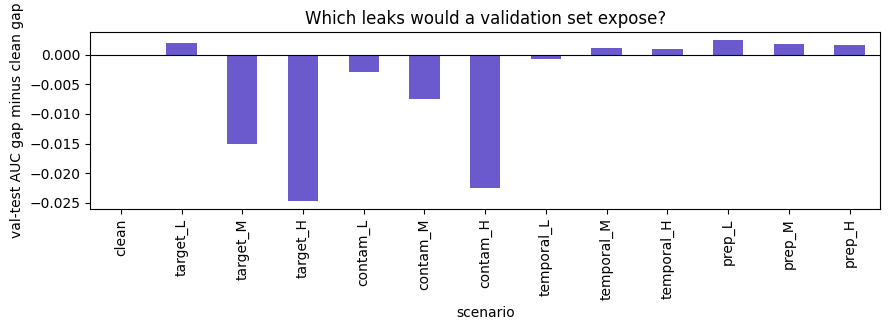

In [31]:
# Cell 32 — Practitioner check: what would a held-out validation set show? (auc_val - auc_test, mean over models)
res["val_minus_test"] = res["auc_val"] - res["auc_test"]
vt = res.groupby("scenario")["val_minus_test"].mean().round(4)
clean_gap = vt["clean"]
vt_tbl = pd.DataFrame({"auc_val_minus_auc_test": vt, "vs_clean_twin": (vt - clean_gap).round(4)})
vt_tbl = vt_tbl.reindex([s["id"] for s in SCENARIOS])
TABLES["validation_vs_test"] = vt_tbl
print(vt_tbl.to_string())
print("\nReading: a leak is exposed by a standard validation set when the val-test gap moves clearly away from the clean-twin gap.\n"
      "Target and preprocessing leaks are applied to validation exactly like to test, so they give no gap; "
      "contamination and temporal leaks are built on the training side and the test period only, so the validation set (B2, neither contaminated nor leaked) "
      "behaves differently from the test set.")
plt.figure(figsize=(9, 3.4)); vt_tbl["vs_clean_twin"].plot.bar(color="slateblue"); plt.axhline(0, color="k", lw=0.8)
plt.ylabel("val-test AUC gap minus clean gap"); plt.title("Which leaks would a validation set expose?")
savefig("validation_vs_test.png")

In [32]:
# Cell 33 — Natural-leak bonus: Customers as a feature (seed 0, outside the benchmark matrix)
scnC = build_scenario(0, "clean", extra_num=["Customers"])
scnC.meta["scenario_id"] = "clean+Customers"
clean0 = build_scenario(0, "clean")
cacheC, rowsC = {}, []
for mn in MODELS:
    bb, met = train_and_eval(scnC, mn)
    rep = run_detector(scnC, bb, cache=cacheC, thresholds=THRESH)
    bb0, met0 = train_and_eval(clean0, mn)
    rowsC.append(dict(model=mn, auc_with_Customers=round(met["auc_test"], 4), auc_clean=round(met0["auc_test"], 4),
                      true_inflation=round(met["auc_test"] - met0["auc_test"], 4), est_inflation=round(rep["est_inflation"], 4),
                      target_score=round(rep["target"]["score"], 3), flagged=rep["target"]["flag"],
                      top_suspects=[s["feature"] for s in rep["target"]["evidence"]["ranked"][:3]]))
print(pd.DataFrame(rowsC).to_string(index=False))
print("\nNote: Customers (visitors that day) is not known when the sales forecast is made, so it is a natural target leak "
      "- exactly the kind of leak that never shows up as a bug in the code.")
del scnC, clean0; gc.collect()

 model  auc_with_Customers  auc_clean  true_inflation  est_inflation  target_score  flagged                  top_suspects
logreg              0.8547     0.8418          0.0129            0.0         0.508    False [Promo, Customers, DayOfWeek]
    rf              0.9054     0.8902          0.0152            0.0         0.510    False [Promo, Customers, DayOfWeek]
   xgb              0.9244     0.8964          0.0280            0.0         0.475    False [Promo, Customers, DayOfWeek]
   mlp              0.8798     0.8343          0.0455            0.0         0.464    False [Promo, Customers, DayOfWeek]

Note: Customers (visitors that day) is not known when the sales forecast is made, so it is a natural target leak - exactly the kind of leak that never shows up as a bug in the code.


6209

In [33]:
# Cell 34 — Leakage-free practice demo
# (a) a combined leaky evaluation: target (sigma=0.5) + contamination (5%) + temporal (15%) + scaler/imputer fitted on train+test
demo_inj = [("contamination", dict(p=0.05, near_frac=0.5)), ("temporal", dict(f=0.15)), ("target", dict(sigma=0.5))]
demo_scopes = dict(scale="pool", impute="pool")
scnD = assemble(0, "combined_demo", demo_inj, scopes=demo_scopes)
clean0 = build_scenario(0, "clean")
cacheD = {}
bbD, metD = train_and_eval(scnD, "xgb")
repD = run_detector(scnD, bbD, cache=cacheD, thresholds=THRESH)
print("detector on the combined leaky setup:", fmt_report(repD))

# (b) corrections driven by the detector's evidence: dedupe, strict time cut, drop flagged features, fit all preprocessing on train only
rt, rv, rte = scnD.raw_train.copy(), scnD.raw_val.copy(), scnD.raw_test.copy()
drop_ids = set(repD["contamination"]["evidence"]["dup_train_row_ids"]) if repD["contamination"]["flag"] else set()
if repD["temporal"]["flag"]:
    drop_ids |= set(repD["temporal"]["evidence"]["post_cut_train_row_ids"])
keep = ~rt["row_id"].isin(drop_ids).to_numpy()
rt = rt[keep].reset_index(drop=True)
feat_drop = [s["feature"] for s in repD["target"]["evidence"]["suspect_features"]] if repD["target"]["flag"] else []
num_cols_fixed = [c for c in NUM_COLS + ["leak_feat"] if c not in feat_drop]
pipe = Pipeline(scopes=None, num_cols=num_cols_fixed).fit(rt, None)             # train-only fit
Xtr, Xva, Xte = pipe.transform(rt), pipe.transform(rv), pipe.transform(rte)
print(f"removed {int((~keep).sum())} train rows (duplicates / post-cut rows); dropped features: {feat_drop or 'none'}")

rows = []
class _S:   # light container for train_and_eval
    pass
fixed = _S(); fixed.X_train, fixed.y_train, fixed.X_val, fixed.y_val, fixed.X_test, fixed.y_test = Xtr, rt["y"].to_numpy(), Xva, rv["y"].to_numpy(), Xte, rte["y"].to_numpy()
fixed.meta = dict(seed=0)
cl = build_scenario(0, "clean")
for mn in MODELS:
    _, m_leak = train_and_eval(scnD, mn)
    _, m_fix = train_and_eval(fixed, mn)
    _, m_cl = train_and_eval(cl, mn)
    rows.append(dict(model=mn, leaky_auc=round(m_leak["auc_test"], 4), corrected_auc=round(m_fix["auc_test"], 4), clean_baseline_auc=round(m_cl["auc_test"], 4)))
demo_tbl = pd.DataFrame(rows).set_index("model")
TABLES["leakage_free_demo"] = demo_tbl
print("\nTest AUC: leaky evaluation vs corrected evaluation vs clean baseline\n", demo_tbl.to_string())
repF = None
if True:
    bbF, _ = train_and_eval(fixed, "xgb")
    ts_f = rt["Date"].to_numpy()
    repF = LeakageDetector(bbF, Xtr, fixed.y_train, Xte, fixed.y_test, pipe.feature_names, ts_train=ts_f, ts_test=rte["Date"].to_numpy(),
                           row_id_train=rt["row_id"].to_numpy(), row_id_test=rte["row_id"].to_numpy(), seed=0, thresholds=THRESH).run()
    print("\ndetector on the corrected setup:", fmt_report(repF))
del scnD, cl, clean0; gc.collect()

# (c) random K-fold vs time-aware CV on the clean pool (preprocessing is re-fitted inside every fold)
from sklearn.model_selection import KFold, TimeSeriesSplit
cv_raw = pool[pool["block"].isin(["B1", "B2", "B3"])].sample(n=min(30000, int((pool["block"] != "B4").sum())), random_state=0).sort_values("Date").reset_index(drop=True)
def cv_auc(splitter):
    out = []
    for tr, te in splitter.split(cv_raw):
        p_ = Pipeline().fit(cv_raw.iloc[tr])
        m = XGBClassifier(n_estimators=150, learning_rate=0.1, max_depth=6, tree_method="hist", n_jobs=-1, random_state=0)
        m.fit(p_.transform(cv_raw.iloc[tr]), cv_raw["y"].iloc[tr])
        out.append(safe_auc(cv_raw["y"].iloc[te], m.predict_proba(p_.transform(cv_raw.iloc[te]))[:, 1]))
    return np.array(out)
auc_kf, auc_ts = cv_auc(KFold(5, shuffle=True, random_state=0)), cv_auc(TimeSeriesSplit(5))
print(f"\nRandom 5-fold CV AUC: {auc_kf.mean():.4f} +- {auc_kf.std():.4f}\nTime-aware (TimeSeriesSplit) AUC: {auc_ts.mean():.4f} +- {auc_ts.std():.4f}\n"
      f"random-split optimism: {auc_kf.mean() - auc_ts.mean():+.4f} AUC")
TABLES["cv_optimism"] = pd.DataFrame({"random_kfold": auc_kf, "time_aware": auc_ts})

detector on the combined leaky setup: targe=0.77* conta=0.00  tempo=0.71* prepr=1.00* | verdict=leaky | est_infl=+0.210 | suspects=['leak_feat']
removed 4912 train rows (duplicates / post-cut rows); dropped features: ['leak_feat']

Test AUC: leaky evaluation vs corrected evaluation vs clean baseline
         leaky_auc  corrected_auc  clean_baseline_auc
model                                               
logreg     0.9558         0.8420              0.8418
rf         0.9663         0.8876              0.8902
xgb        0.9715         0.8941              0.8964
mlp        0.9639         0.8255              0.8343

detector on the corrected setup: targe=0.50  conta=0.00  tempo=0.00  prepr=0.00  | verdict=clean | est_infl=+0.000 | suspects=[]

Random 5-fold CV AUC: 0.9304 +- 0.0042
Time-aware (TimeSeriesSplit) AUC: 0.8943 +- 0.0296
random-split optimism: +0.0360 AUC


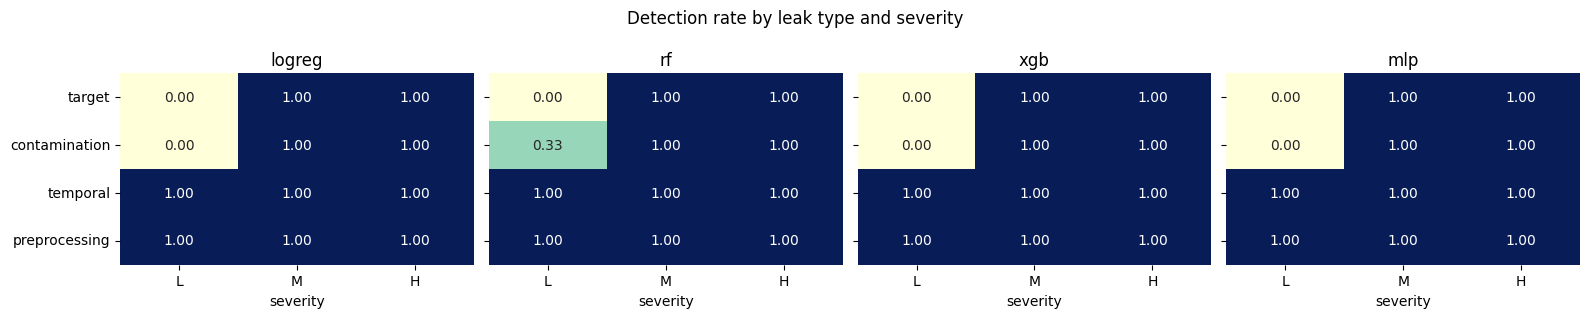

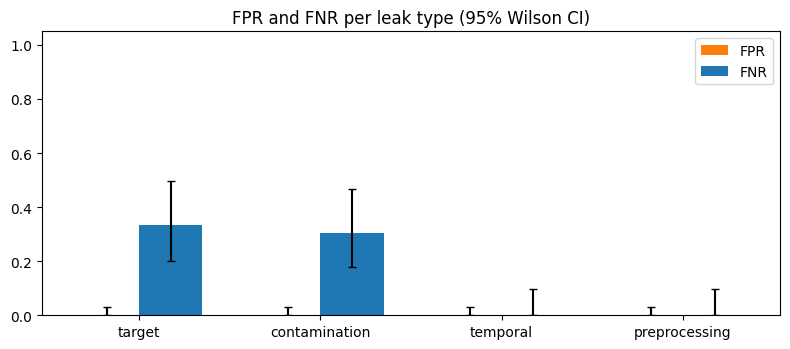

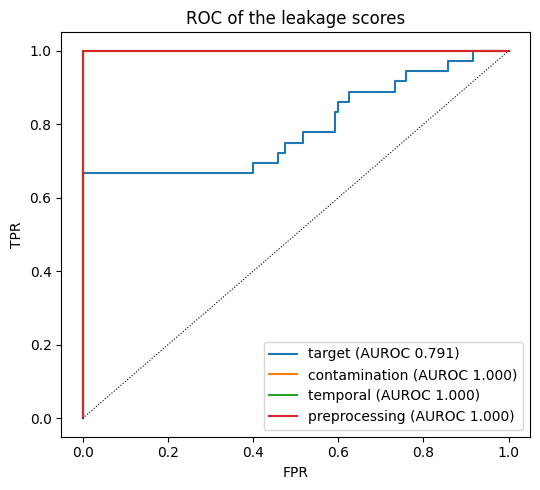

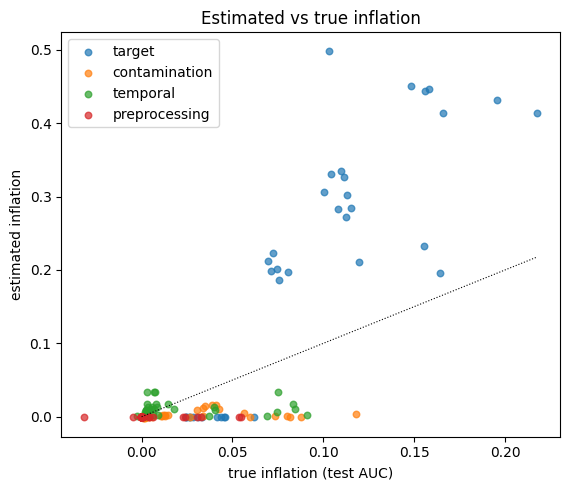

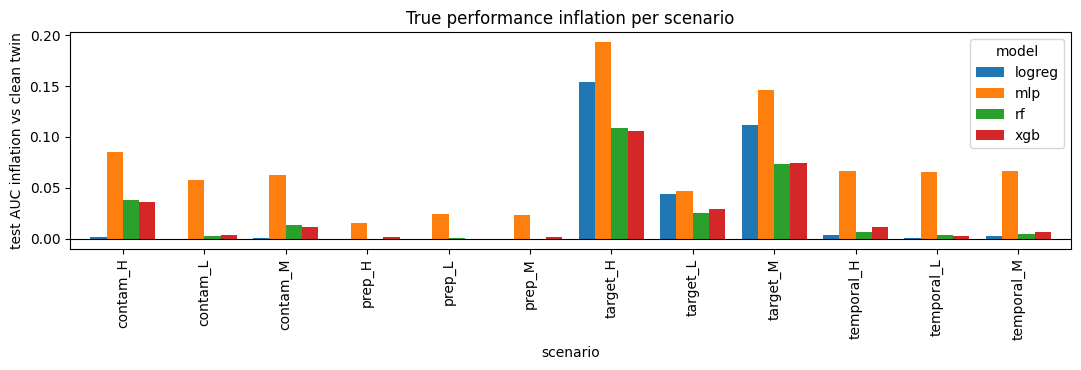

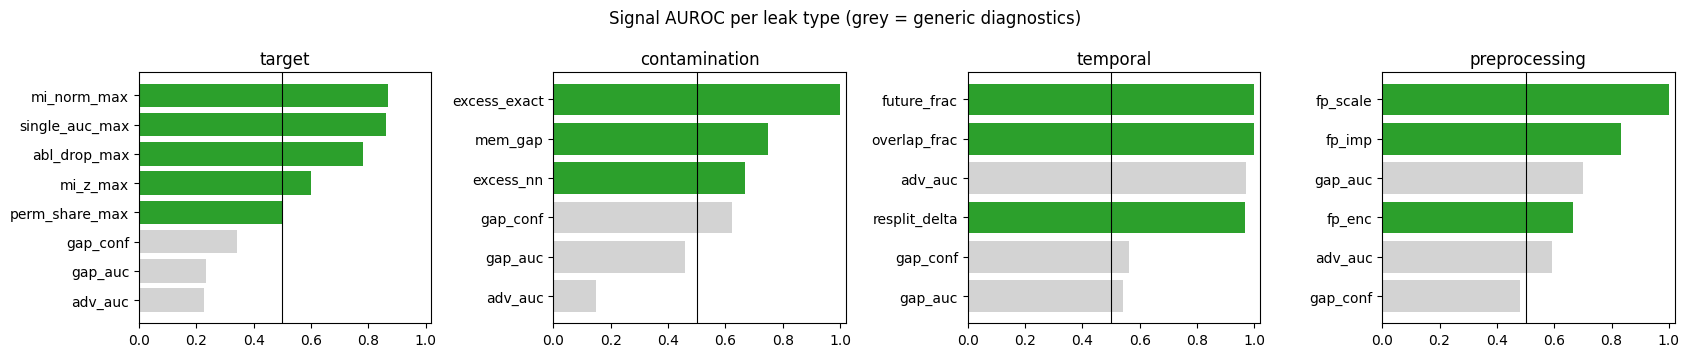

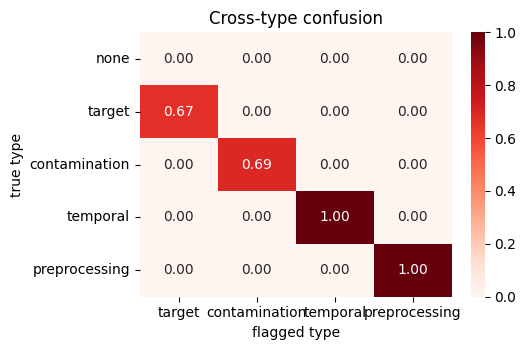

figures saved to /content/results/figures


In [34]:
# Cell 35 — Figures (PNG in results/figures/)
sev_order = ["L", "M", "H"]
# 1) detection-rate heatmap (type x severity), one panel per model
fig, axs = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, mn in zip(axs, MODELS):
    s = own[own["model"] == mn]
    hm = s.groupby(["leak_type_true", "variant"])["own_flag"].mean().unstack().reindex(index=LEAK_TYPES, columns=sev_order)
    sns.heatmap(hm, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="YlGnBu", cbar=False, ax=ax); ax.set_title(mn); ax.set_xlabel("severity"); ax.set_ylabel("")
fig.suptitle("Detection rate by leak type and severity")
savefig("fig1_detection_heatmap.png")

# 2) FPR / FNR per type with Wilson CIs
bt = TABLES["detection_by_type"].loc[LEAK_TYPES]
fig, ax = plt.subplots(figsize=(8, 3.6)); w = 0.35; x = np.arange(len(LEAK_TYPES))
for off, k, col in ((-w / 2, "FPR", "tab:orange"), (w / 2, "FNR", "tab:blue")):
    v = bt[k].astype(float).values
    err = np.vstack([v - bt[f"{k}_lo"].astype(float).values, bt[f"{k}_hi"].astype(float).values - v])
    ax.bar(x + off, v, w, yerr=np.clip(err, 0, None), capsize=3, label=k, color=col)
ax.set_xticks(x); ax.set_xticklabels(LEAK_TYPES); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title("FPR and FNR per leak type (95% Wilson CI)")
savefig("fig2_fpr_fnr.png")

# 3) ROC curves of the four leakage scores
plt.figure(figsize=(5.5, 5))
for t in LEAK_TYPES:
    fpr, tpr, _ = roc_curve(res[f"truth_{t}"], res[f"score_{t}"])
    plt.plot(fpr, tpr, label=f"{t} (AUROC {safe_auc(res[f'truth_{t}'], res[f'score_{t}']):.3f})")
plt.plot([0, 1], [0, 1], "k:", lw=0.8); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title("ROC of the leakage scores")
savefig("fig3_score_roc.png")

# 4) estimated vs true inflation
plt.figure(figsize=(5.8, 5))
for t in LEAK_TYPES:
    s = res[res["leak_type_true"] == t]
    plt.scatter(s["infl_auc"], s["est_by_type"].apply(lambda d_: d_[t]), s=22, alpha=0.7, label=t)
lim = max(res["infl_auc"].max(), 0.05); plt.plot([0, lim], [0, lim], "k:", lw=0.8)
plt.xlabel("true inflation (test AUC)"); plt.ylabel("estimated inflation"); plt.legend(); plt.title("Estimated vs true inflation")
savefig("fig4_est_vs_true.png")

# 5) true inflation bars per scenario x model
ti = TABLES["true_inflation_auc"].drop(index="clean")
ti.plot.bar(figsize=(11, 3.8), width=0.8); plt.ylabel("test AUC inflation vs clean twin"); plt.title("True performance inflation per scenario"); plt.axhline(0, color="k", lw=0.8)
savefig("fig5_true_inflation.png")

# 6) signal contribution
sg = TABLES["signal_auroc"]
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6), sharex=True)
for ax, t in zip(axs, LEAK_TYPES):
    s = sg[sg["detects"] == t].sort_values("AUROC")
    ax.barh(s["signal"], s["AUROC"], color=["lightgray" if g_ else "tab:green" for g_ in s["generic"]]); ax.axvline(0.5, color="k", lw=0.8); ax.set_title(t); ax.set_xlim(0, 1.02)
fig.suptitle("Signal AUROC per leak type (grey = generic diagnostics)")
savefig("fig6_signal_contribution.png")

# 7) cross-type confusion
plt.figure(figsize=(5.5, 3.6)); sns.heatmap(TABLES["cross_type_confusion"].astype(float), annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1)
plt.xlabel("flagged type"); plt.ylabel("true type"); plt.title("Cross-type confusion")
savefig("fig7_confusion.png")
print("figures saved to", FIG_DIR)

## Conclusions and caveats

*(The numbers below are produced by the cell that follows; read them together with the tables above.)*

**What was detected reliably.** See the detection table (cell 27) and the per-scenario detection rates (cell 31). In the intended design, high-severity target leakage (a near-perfect label proxy), medium/high contamination (excess exact or near-duplicate overlap), temporal leakage (a timestamp is supplied, so future rows are directly visible) and pooled-fit preprocessing (exact scaler / imputer / encoder fingerprints) are the easiest to expose.

**Per-type performance inflation.** Cell 28 reports the true inflation (leaky minus clean twin) per scenario and model, and how closely the black-box remediation estimate tracks it. Preprocessing leakage barely changes accuracy and is deliberately not estimated.

**Limits of pipeline-free detection.** Low-severity target leakage looks like a legitimately useful feature; very small contamination (1% of test rows) is hidden by the baseline-excess requirement; subtle preprocessing leakage is only visible through exact fingerprints, so any extra transformation (rounding, clipping, a different scaler) after the leaky fit can erase it; adversarial validation and train-test gaps are generic distribution-shift diagnostics and are not specific to any single leak type.

**Leakage-free recommendations.** Deduplicate before splitting; split strictly by time and use time-aware cross-validation; fit every preprocessing step (imputer, scaler, encoder) on the training fold only; drop or audit features that are unknown at prediction time (such as `Customers`); keep the validation and test sets processed with train-only statistics.

**Known caveats.**
* Store identity appears in train and test (natural, not injected).
* The label is relative to a B1 store median, so the positive rate drifts slightly over time.
* Preprocessing leakage barely changes accuracy; it is detected from fingerprints, not from performance.
* Detection of temporal leakage is easy here because a timestamp is supplied. Without it the module abstains.
* Rows of one scenario evaluated with four models share their data-level signals, so the FPR/FNR confidence intervals (which treat rows as independent) are optimistic. Raise `N_SEEDS` for tighter estimates.

In [35]:
# Cell 36 — Export: tables, summary, zip, download
for name, tbl in TABLES.items():
    tbl.to_csv(os.path.join(RESULTS_DIR, f"table_{name}.csv"))
res.drop(columns=["est_by_type"]).to_csv(RES_INFL_CSV, index=False)

bt = TABLES["detection_by_type"]
print("=== Summary ===")
for t in LEAK_TYPES + ["OVERALL (clean vs leaky)"]:
    r = bt.loc[t]
    print(f"{t:26s} accuracy {r['accuracy']:.3f} | FPR {r['FPR']:.3f} [{r['FPR_lo']:.2f},{r['FPR_hi']:.2f}] | FNR {r['FNR']:.3f} [{r['FNR_lo']:.2f},{r['FNR_hi']:.2f}]")
print("\nMean true AUC inflation by leak type:", {k: round(v, 4) for k, v in res[res["leak_type_true"] != "none"].groupby("leak_type_true")["infl_auc"].mean().items()})
print("Frozen thresholds:", FROZEN_THRESH)

zip_path = os.path.join(os.path.dirname(RESULTS_DIR.rstrip("/")) or ".", "leakage_results.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(RESULTS_DIR):
        for fn in files:
            full = os.path.join(root, fn)
            zf.write(full, os.path.relpath(full, os.path.dirname(RESULTS_DIR)))
print("\nzip written:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(zip_path)                      # browser download, not Drive
except Exception as e:
    print("(not in Colab: download skipped)", type(e).__name__)

=== Summary ===
target                     accuracy 0.923 | FPR 0.000 [0.00,0.03] | FNR 0.333 [0.20,0.50]
contamination              accuracy 0.929 | FPR 0.000 [0.00,0.03] | FNR 0.306 [0.18,0.47]
temporal                   accuracy 1.000 | FPR 0.000 [0.00,0.03] | FNR 0.000 [0.00,0.10]
preprocessing              accuracy 1.000 | FPR 0.000 [0.00,0.03] | FNR 0.000 [0.00,0.10]
OVERALL (clean vs leaky)   accuracy 0.853 | FPR 0.000 [0.00,0.24] | FNR 0.160 [0.11,0.23]

Mean true AUC inflation by leak type: {'contamination': 0.0259, 'preprocessing': 0.0055, 'target': 0.0926, 'temporal': 0.0201}
Frozen thresholds: {'target': 0.5752622385457579, 'contamination': 0.5, 'temporal': 0.5, 'preprocessing': 0.5}

zip written: /content/leakage_results.zip (2.3 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>